In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt 

In [2]:
path_wd = Path.cwd()
path_dir = path_wd.parent

In [4]:
pricesDFS = pd.read_csv(path_dir / 'data/dfs-utilisation-report-past.csv', parse_dates=['Delivery Date'])
# pricesDFS = pricesDFS[(pricesDFS['Status'] != 'Rejected') & (pricesDFS['Service Requirement Type'] == 'Live')]
pricesDFS

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_15004\788758026.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  pricesDFS = pd.read_csv(path_dir / 'data/dfs-utilisation-report-past.csv', parse_dates=['Delivery Date'])


,Delivery Date,Registered DFS Participant,DFS Unit ID,DFS Volume MW,From,To,Service Requirement Type,Despatch Time,Utilisation Price GBP per MWh,Status,...,West Midlands,London,East England,South East England,South West England,Southern England,"North Wales, Merseyside and Cheshire",South Wales,Other,Total
0,2024-03-21,AXLE ENERGY LIMITED,Axle-01,10,17:30,18:00,Test,within-day 2,698,Accepted,...,0.000,0.0000,0.00000,0.0,0.000,0.0000,0.00000,0.0,10.0,10
1,2024-03-21,CONRAD ENERGY (TRADING) LIMITED,CONRAD-02,3,17:30,18:00,Test,within-day 2,497,Accepted,...,0.000,0.0000,0.00000,0.0,3.000,0.0000,0.00000,0.0,0.0,3
2,2024-03-21,CONRAD ENERGY (TRADING) LIMITED,CONRAD-02,3,18:30,19:00,Test,within-day 2,497,Accepted,...,0.000,0.0000,0.00000,0.0,3.000,0.0000,0.00000,0.0,0.0,3
3,2024-03-21,CUB (UK) LTD,CUB-01,2,18:30,19:00,Test,within-day 2,748,Accepted,...,0.192,0.1125,0.39675,0.0,0.012,0.0675,0.13725,0.0,0.0,2
4,2024-03-21,DRAX ENERGY SOLUTIONS LIMITED,DRAX-02,4,17:30,18:00,Test,within-day 2,725,Accepted,...,0.000,0.8000,0.80000,0.8,0.000,1.6000,0.00000,0.0,0.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1215,2023-11-16,UTILITA ENERGY LIMITED,UTILIT-01,2,17:30,18:00,Test,day-ahead,3000,Accepted,...,0.000,0.0000,0.00000,0.0,0.000,0.0000,0.00000,0.0,2.0,2
1216,2023-11-16,OCTOPUS ENERGY LIMITED,OCTOP-03,12,17:30,18:00,Test,day-ahead,4000,Rejected,...,1.000,0.0000,2.00000,1.0,1.000,2.0000,0.00000,0.0,0.0,12
1217,2023-11-16,OCTOPUS ENERGY LIMITED,OCTOP-03,12,18:00,18:30,Test,day-ahead,4000,Rejected,...,1.000,0.0000,2.00000,1.0,1.000,2.0000,0.00000,0.0,0.0,12
1218,2023-11-16,OCTOPUS ENERGY LIMITED,OCTOP-04,12,17:30,18:00,Test,day-ahead,5000,Rejected,...,1.000,0.0000,2.00000,1.0,1.000,2.0000,0.00000,0.0,0.0,12


In [12]:
pricesDFS = pd.read_csv(path_dir / 'data/dfs-utilisation-report.csv') ##the past report only has live events till 2023-12-01
pricesDFS = pricesDFS[(pricesDFS['Status'] != 'Rejected') & (pricesDFS['Service Requirement Type'] == 'Live')]
pricesDFS['date'] = pd.to_datetime(pricesDFS['Delivery Date'] + ' ' + pricesDFS['From'])
pricesDFS.set_index('date', inplace=True)
#volumes residential vs c&i
pricesDFS

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_15004\425362683.py:3: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  pricesDFS['date'] = pd.to_datetime(pricesDFS['Delivery Date'] + ' ' + pricesDFS['From'])


,Delivery Date,Registered DFS Participant,DFS Unit ID,DFS Volume MW,From,To,Service Requirement Type,Utilisation Price GBP per MWh,Status,North Scotland,...,West Midlands,London,East England,South East England,South West England,Southern England,North Wales Merseyside and Cheshire,South Wales,Other,Total
date,,,,,,,,,,,,,,,,,,,,,
2025-07-29 20:00:00,29/07/2025,INFINIS LIMITED,INFINS-01,8.1,20:00,20:30,Live,103.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.1,8.1
2025-07-29 20:30:00,29/07/2025,INFINIS LIMITED,INFINS-01,8.0,20:30,21:00,Live,103.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,8.0
2025-07-29 20:00:00,29/07/2025,INFINIS LIMITED,INFINS-02,3.2,20:00,20:30,Live,104.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.2,3.2
2025-07-29 20:30:00,29/07/2025,INFINIS LIMITED,INFINS-02,2.9,20:30,21:00,Live,104.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.9,2.9
2025-07-29 20:00:00,29/07/2025,INFINIS LIMITED,INFINS-03,2.4,20:00,20:30,Live,105.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.4,2.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-03 16:30:00,03/12/2024,GRIDIMP LTD,GRIMP-01,2.0,16:30,17:00,Live,500.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0
2024-12-03 17:00:00,03/12/2024,GRIDIMP LTD,GRIMP-01,2.0,17:00,17:30,Live,500.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0
2024-12-03 17:30:00,03/12/2024,GRIDIMP LTD,GRIMP-01,2.0,17:30,18:00,Live,500.0,Accepted,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_15004\1689556350.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


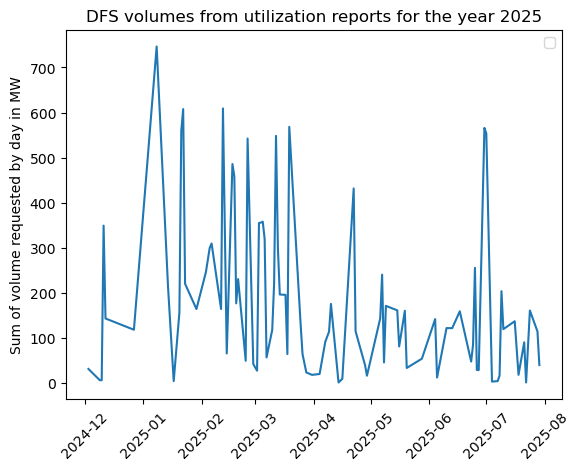

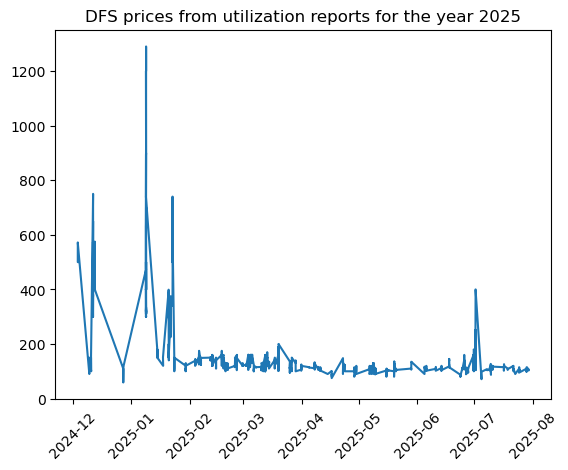

In [17]:
plt.plot(pricesDFS['DFS Volume MW'].groupby(pricesDFS.index.date).sum())
plt.xticks(rotation=45)


plt.ylabel('Sum of volume requested by day in MW')
plt.title('DFS volumes from utilization reports for the year 2025')
plt.legend()
plt.show()

plt.plot(pricesDFS.index, pricesDFS['Utilisation Price GBP per MWh'])
plt.title('DFS prices from utilization reports for the year 2025')

plt.xticks(rotation=45)

plt.show() 

# plt.plot(pricesDFS.index, pricesDFS['DFS Volume MW'])
# plt.xticks(rotation=45)

# plt.show()

In [18]:
pricesENAPSYS = pd.read_csv(path_dir / 'data/prices-ancillary-elec_ENAPSYS.csv', index_col=0, header=[0, 1])
pricesENAPSYS.index = pd.to_datetime(pricesENAPSYS.index.str.replace(r'[\[\]\(\)\{\}]', '', regex=True),
                              dayfirst = True)
pricesENAPSYS

Date (WET),PBR,NBR,DLH,Dynamic Containment High,Dynamic Containment Low,Dynamic FFR,Dynamic Moderation High,Dynamic Moderation Low,Dynamic Regulation High,Dynamic Regulation Low,...,LFS,PQR,NQR,Static FFR,STOR (DAY AHEAD),STOR (HISTORIC),NIV CHASING 1HR PER DAY EQUIV,MIDP 1HR PER DAY EQUIV,DAY-AHEAD 1HR PER DAY EQUIV,HHRPD 1HR PER DAY EQUIV
,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,...,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/d,GBP/MW/d,GBP/MW/d,GBP/MW/d
2020-01-01 00:00:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.22,0.0,0.0,0.0
2020-01-01 00:30:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.23,0.0,0.0,0.0
2020-01-01 01:00:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.00,0.0,0.0,0.0
2020-01-01 01:30:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.00,0.0,0.0,0.0
2020-01-01 02:00:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.00,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-30 21:30:00,3.37,NaN,NaN,0.79,6.70,NaN,-0.32,11.54,-10.45,27.47,...,NaN,13.88,1.0,7.00,1.49,NaN,NaN,NaN,NaN,NaN
2025-06-30 22:00:00,1.00,NaN,NaN,1.60,2.12,NaN,0.43,6.17,-8.22,17.89,...,NaN,6.74,1.0,7.00,NaN,NaN,NaN,NaN,NaN,NaN
2025-06-30 22:30:00,1.00,NaN,NaN,1.60,2.12,NaN,0.43,6.17,-8.22,17.89,...,NaN,6.60,1.0,7.00,NaN,NaN,NaN,NaN,NaN,NaN


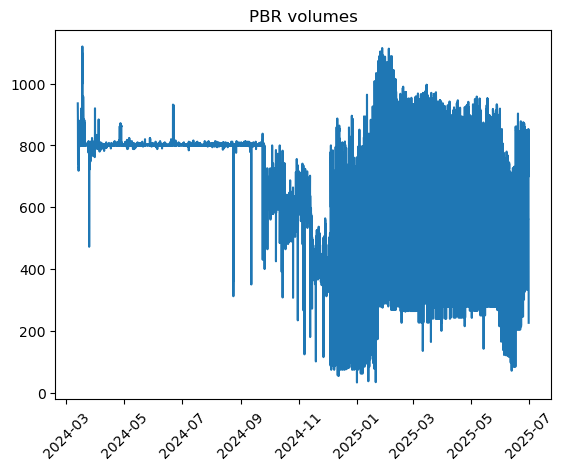

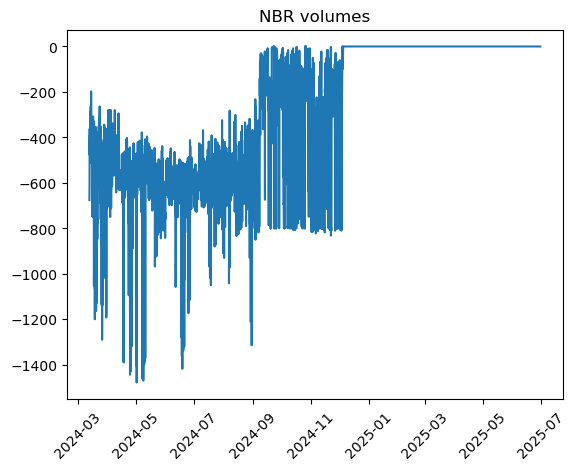

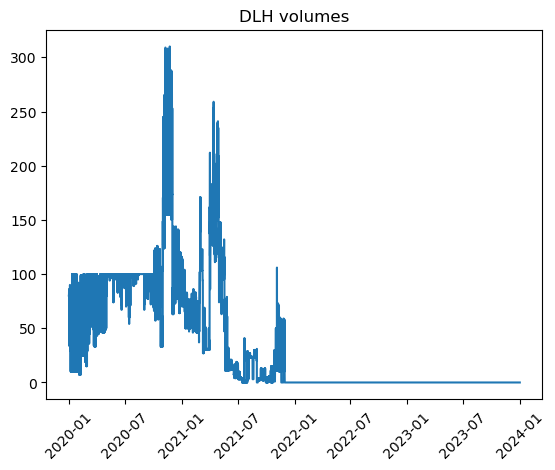

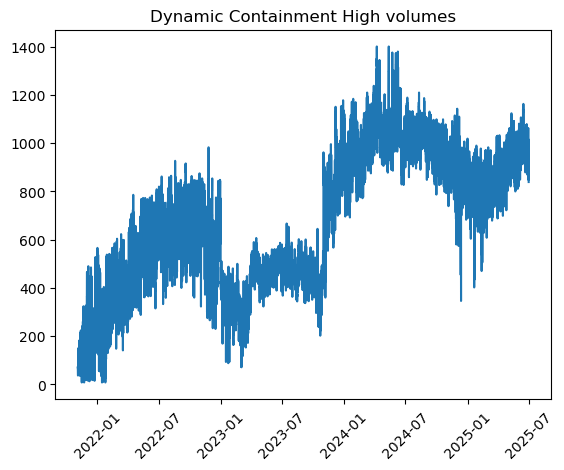

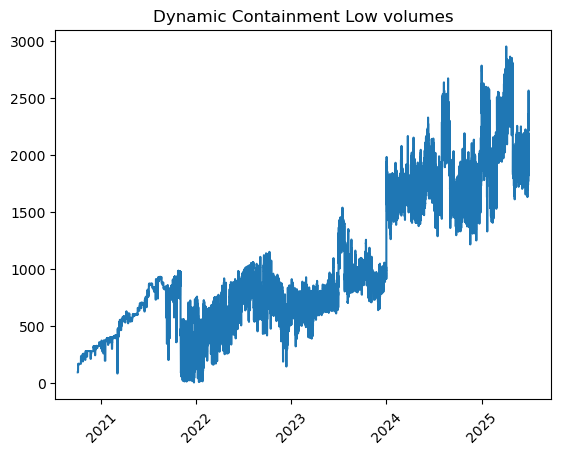

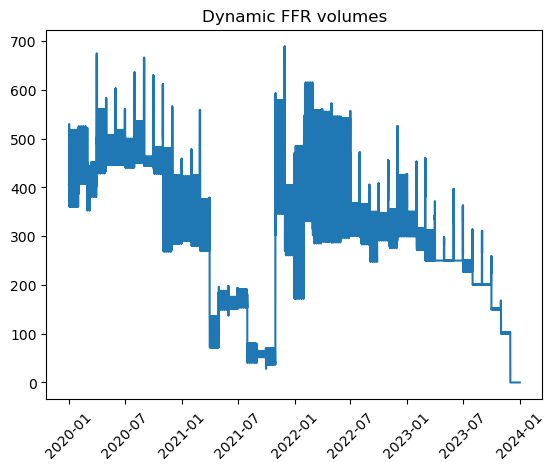

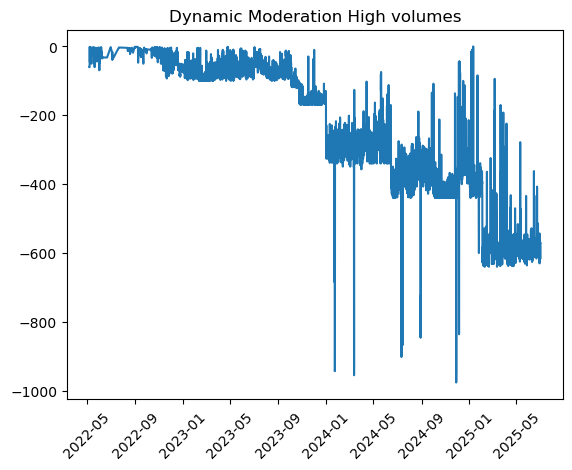

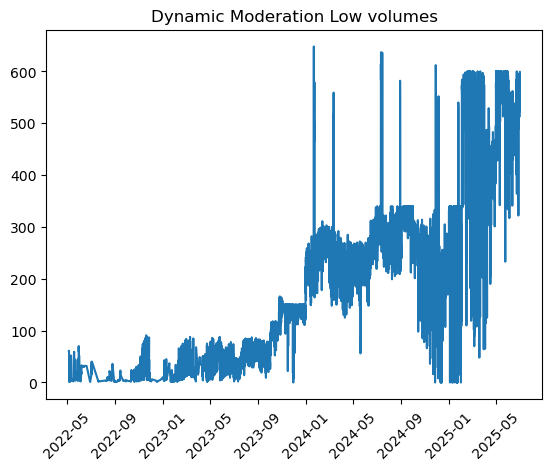

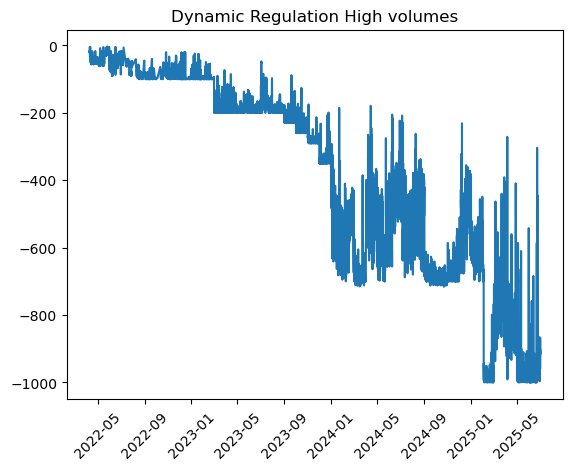

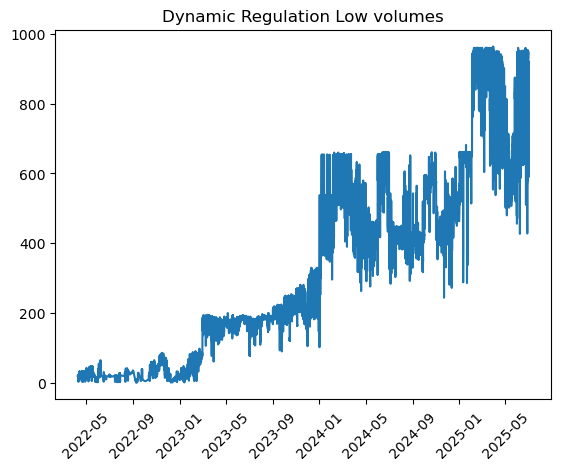

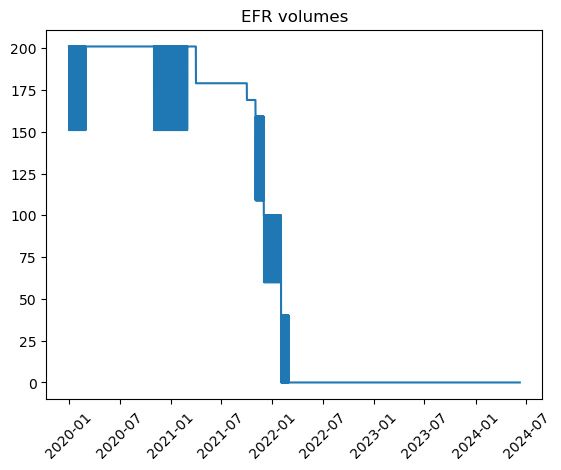

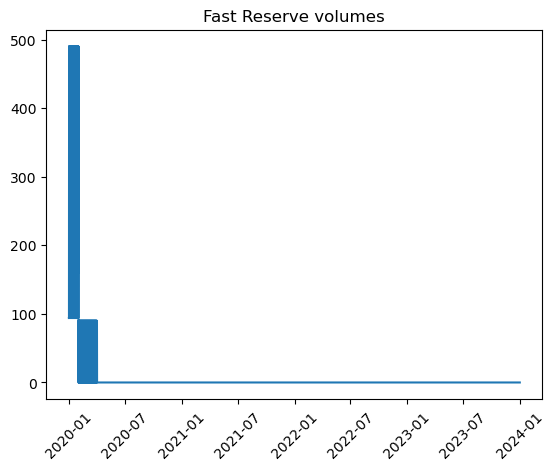

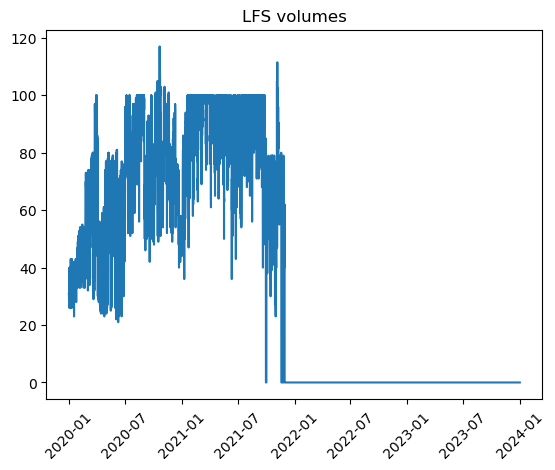

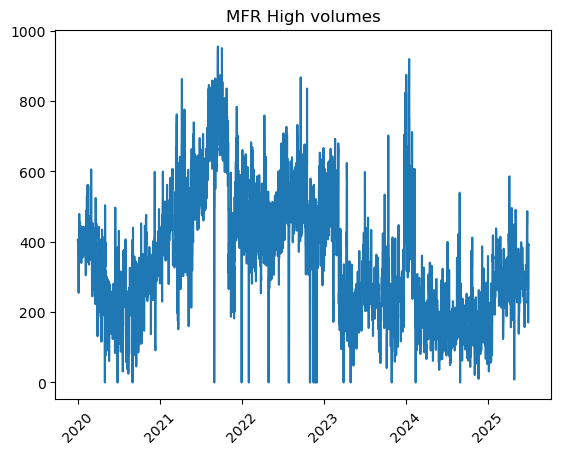

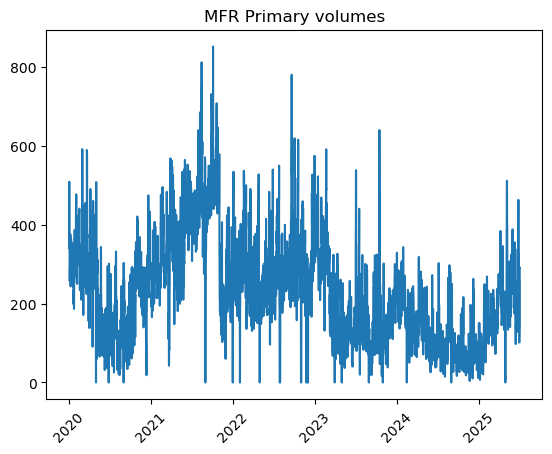

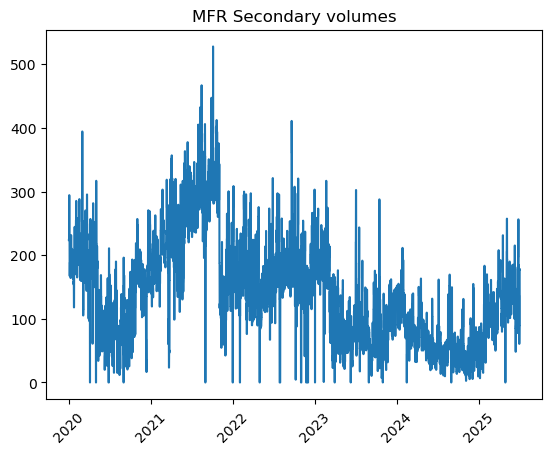

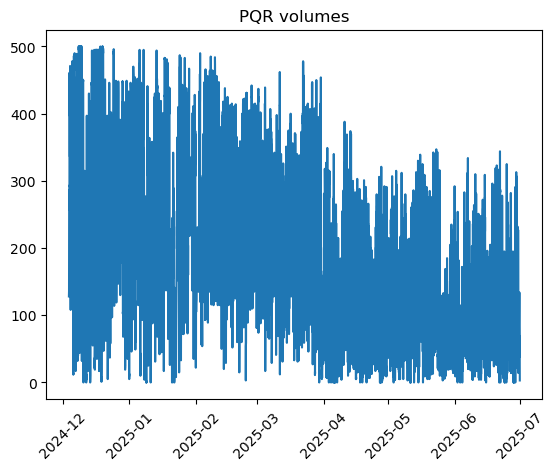

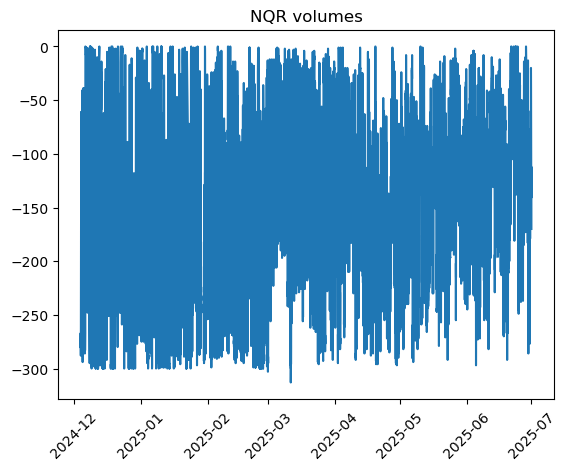

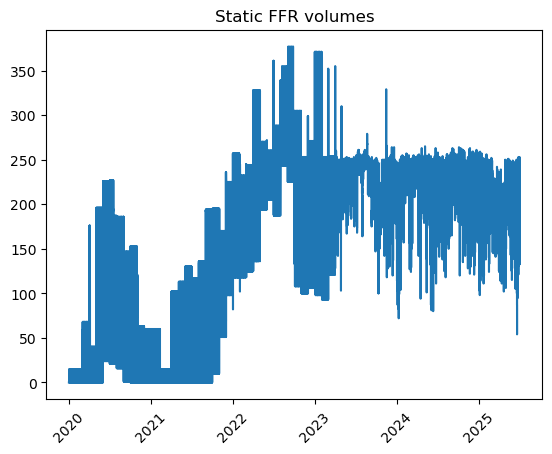

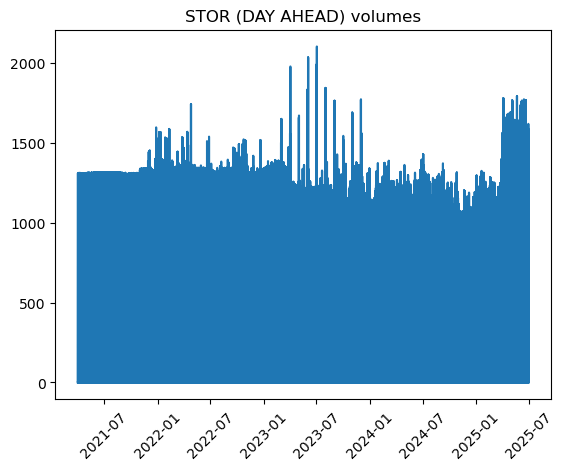

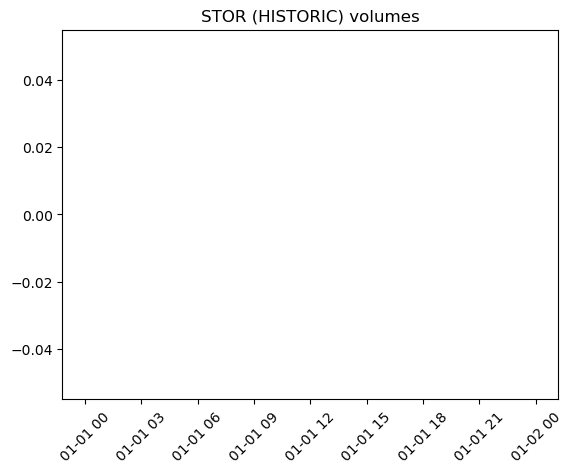

In [69]:
volumesENAPSYS = pd.read_csv(path_dir / 'data/volumes-ancillary-elec_ENAPSYS.csv', index_col=0, header=[0, 1])
volumesENAPSYS.index = pd.to_datetime(volumesENAPSYS.index.str.replace(r'[\[\]\(\)\{\}]', '', regex=True),
                              dayfirst = True)
volumesENAPSYS

for service in list(volumesENAPSYS.columns.get_level_values(0)):

    filter_service = volumesENAPSYS[service].dropna()

    plt.plot(filter_service)
    plt.xticks(rotation=45) 
    plt.title(f'{service} volumes')
    plt.show()
    

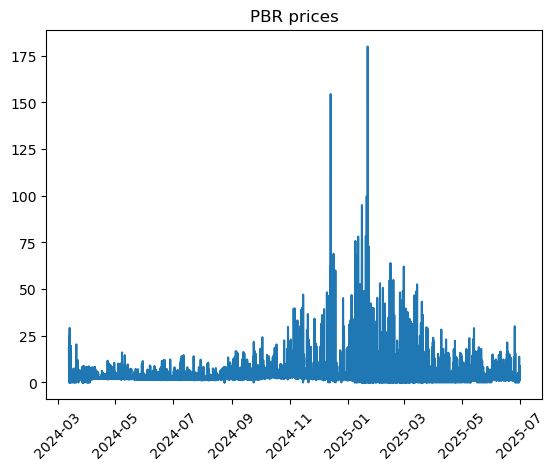

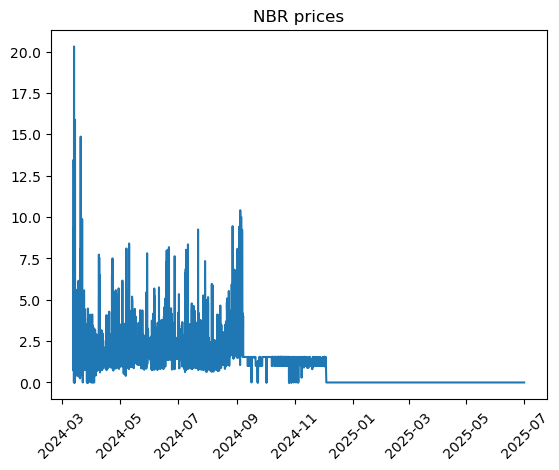

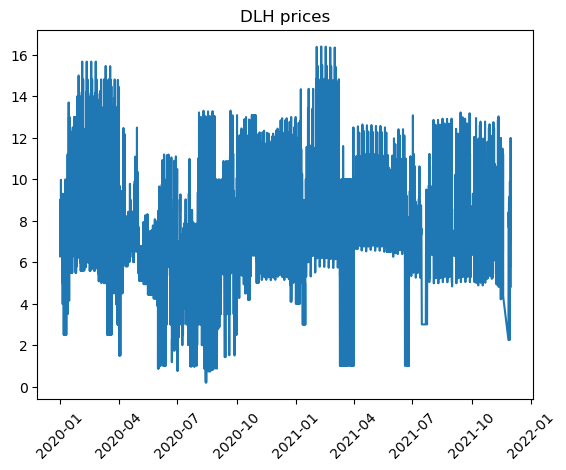

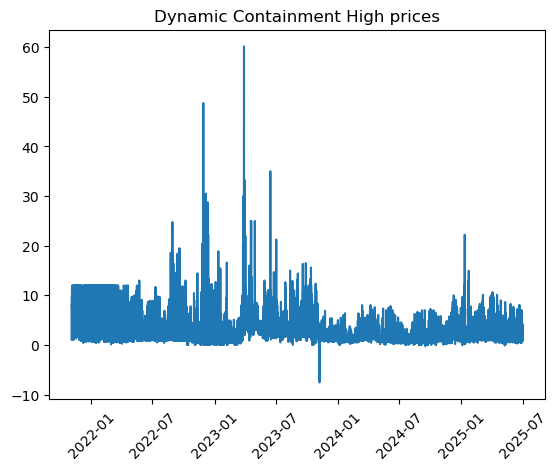

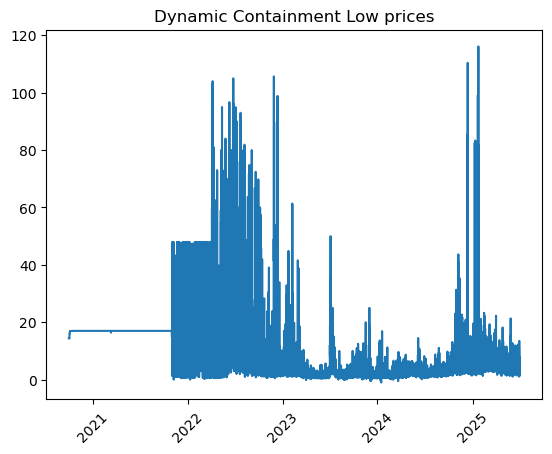

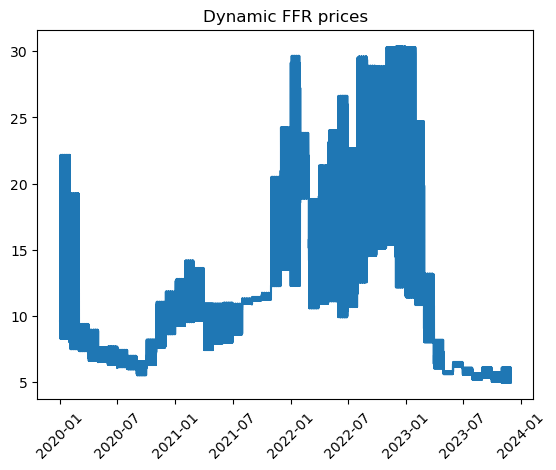

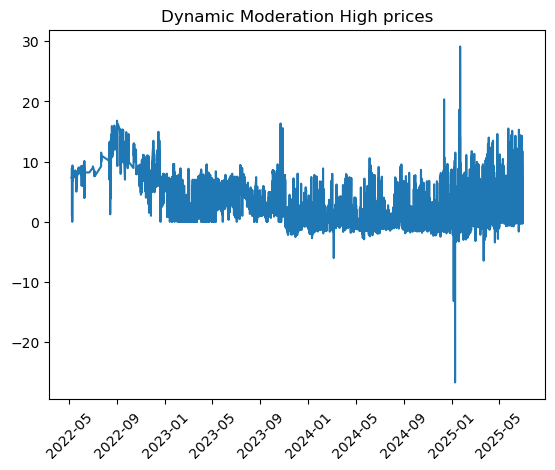

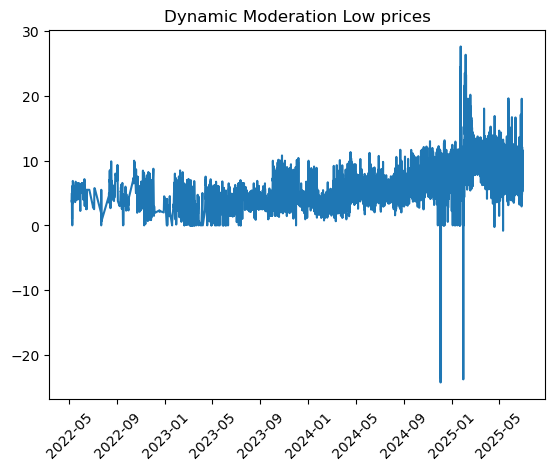

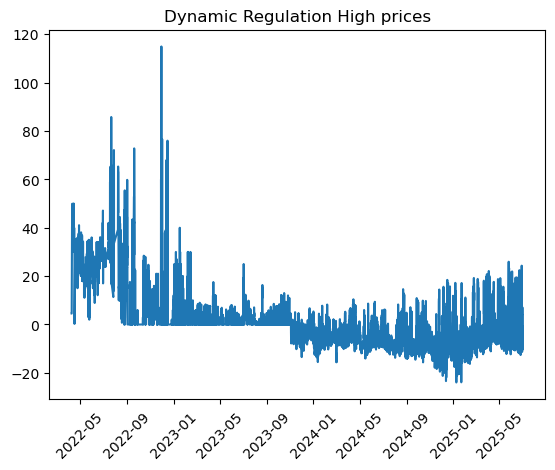

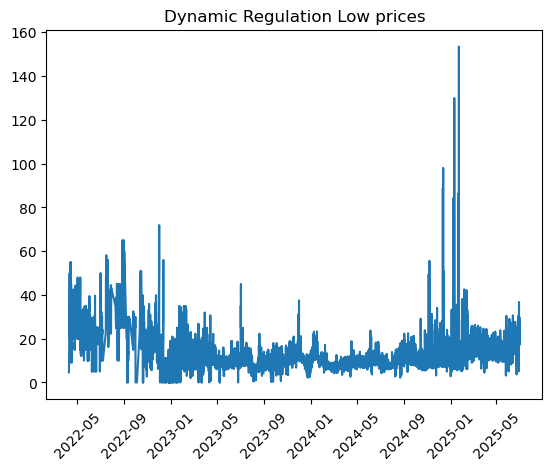

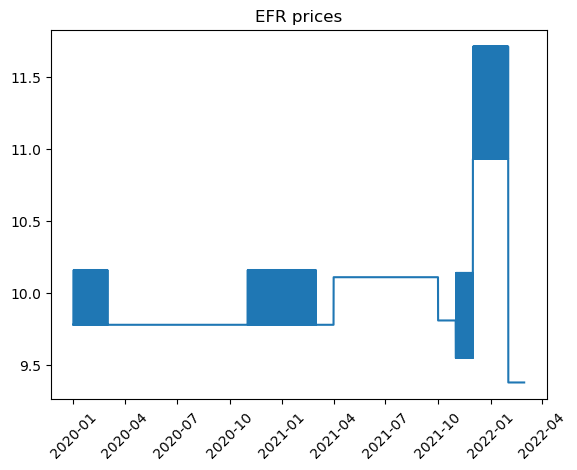

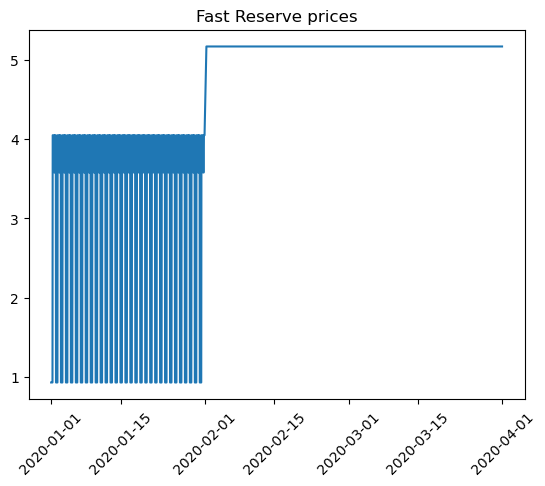

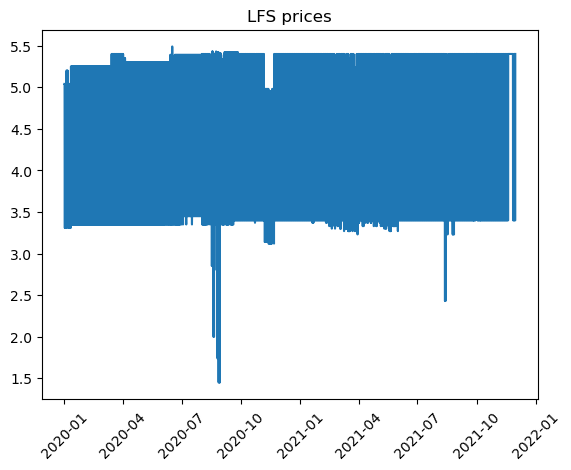

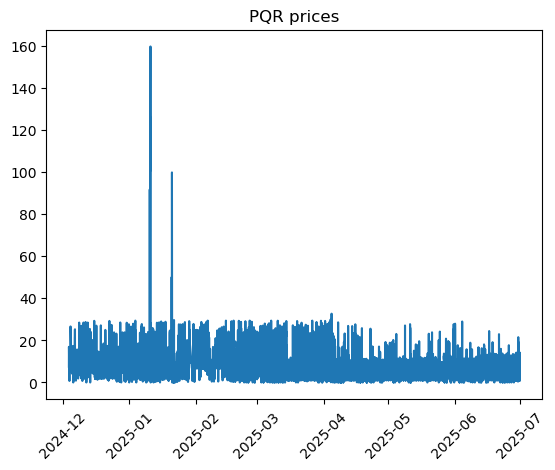

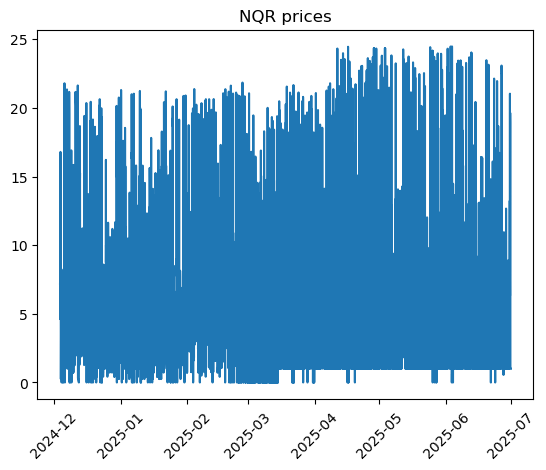

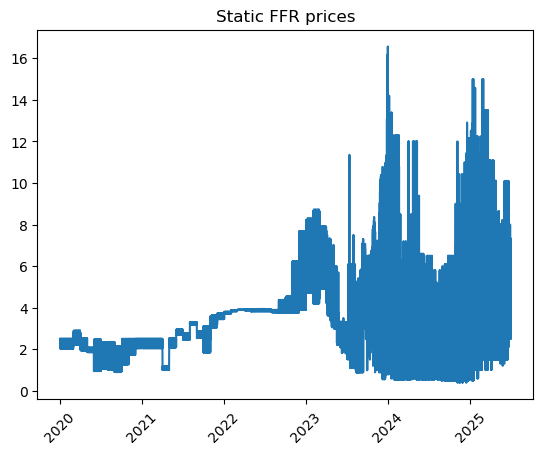

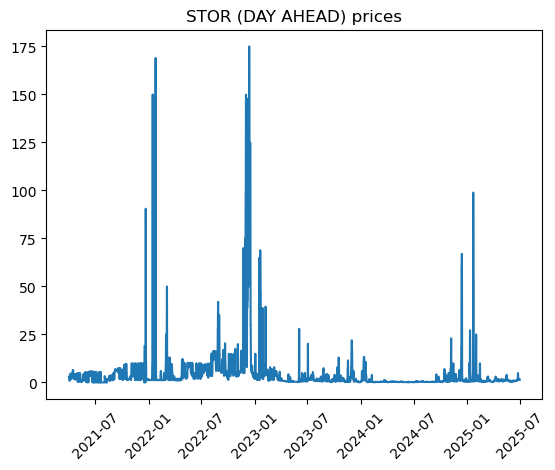

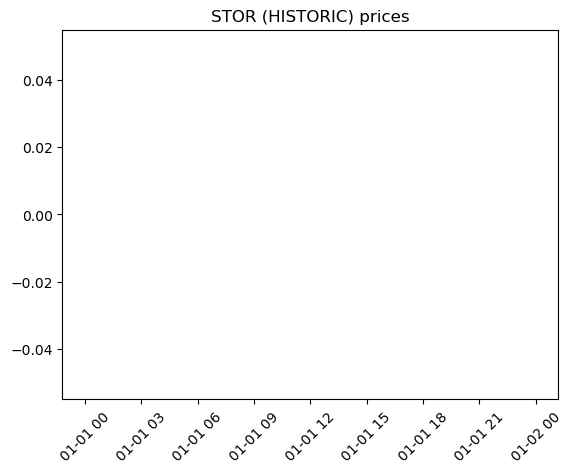

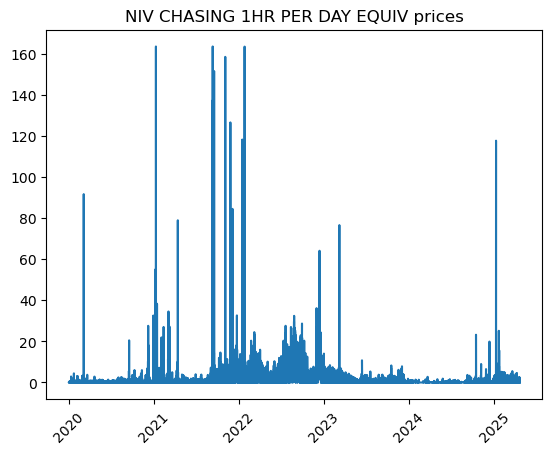

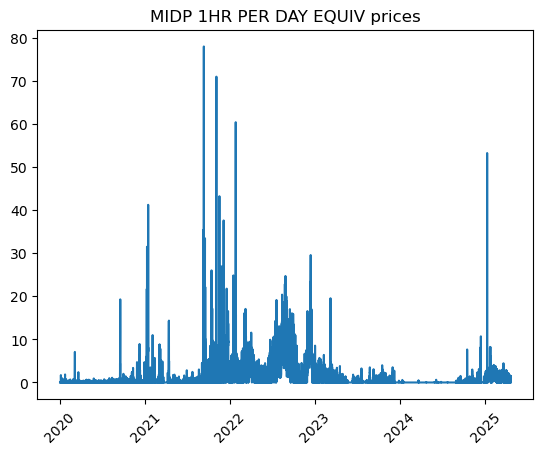

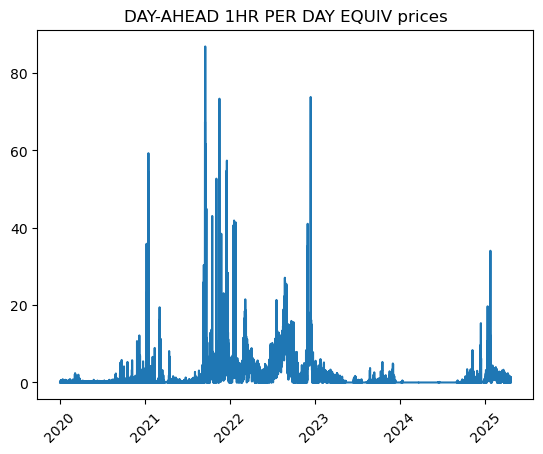

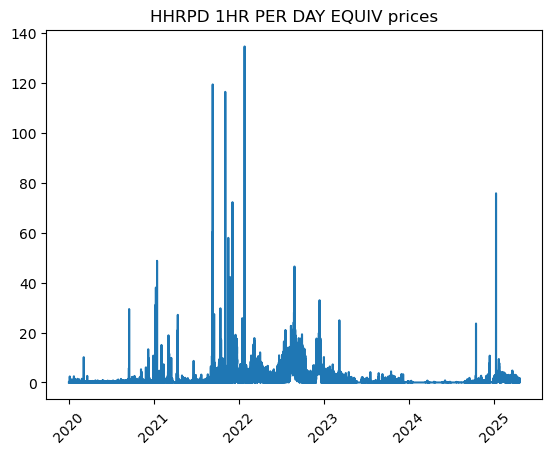

In [ ]:
for service in list(pricesENAPSYS.columns.get_level_values(0)):

    filter_service = pricesENAPSYS[service].dropna()

    plt.plot(filter_service)
    plt.xticks(rotation=45) 
    plt.title(f'{service} prices')
    plt.show()
    


In [54]:
pricesNESO = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-2021.csv', parse_dates= ['Delivery Start', 'Delivery End'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

print(pricesNESO['Delivery Start'].min(), pricesNESO['Delivery End'].max())
pricesNESO

2021-09-15 23:00:00 2023-11-02 23:00:00


,Company,Unit Name,EFA Date,Delivery Start,Delivery End,EFA,Service,Cleared Volume,Clearing Price,Technology Type,Location,Cancelled
0,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-15 23:00:00,2021-09-16 03:00:00,1,DCL,1,17.00,NaN,NaN,NaN
1,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 03:00:00,2021-09-16 07:00:00,2,DCL,1,17.00,NaN,NaN,NaN
2,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 07:00:00,2021-09-16 11:00:00,3,DCL,1,17.00,NaN,NaN,NaN
3,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 11:00:00,2021-09-16 15:00:00,4,DCL,1,17.00,NaN,NaN,NaN
4,ANCALA ENERGY STORAGE LIMITED,ANSC-001,2021-09-16,2021-09-16 15:00:00,2021-09-16 19:00:00,5,DCL,1,17.00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
397657,ZENOBE ENERGY LIMITED,DBESSH-33,2023-11-02,2023-11-02 19:00:00,2023-11-02 23:00:00,6,DCL,7,1.50,Batteries,BN44,NaN
397658,ZENOBE ENERGY LIMITED,ZEN02A,2023-11-02,2023-11-02 07:00:00,2023-11-02 11:00:00,3,DRL,16,10.60,Batteries,CO10,NaN
397659,ZENOBE ENERGY LIMITED,ZEN02A,2023-11-02,2023-11-02 11:00:00,2023-11-02 15:00:00,4,DRL,17,10.77,Batteries,CO10,NaN
397660,ZENOBE ENERGY LIMITED,ZEN02A,2023-11-02,2023-11-02 15:00:00,2023-11-02 19:00:00,5,DRL,14,11.50,Batteries,CO10,NaN


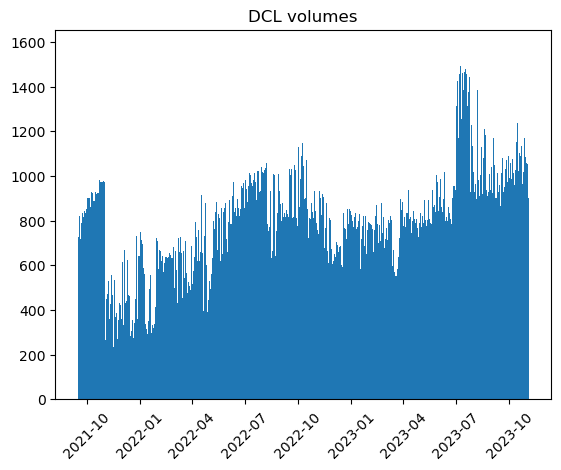

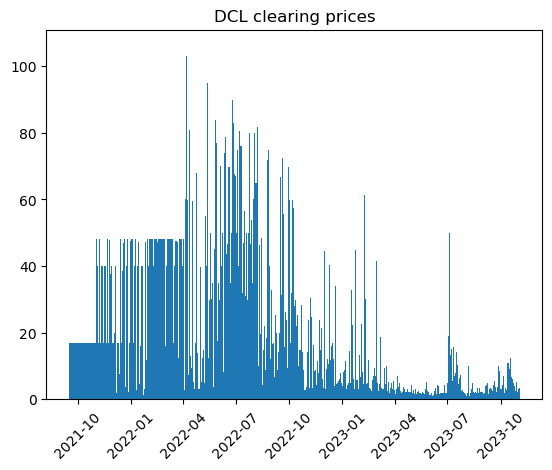

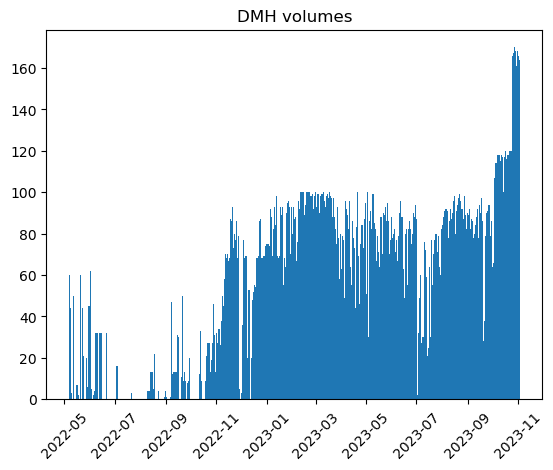

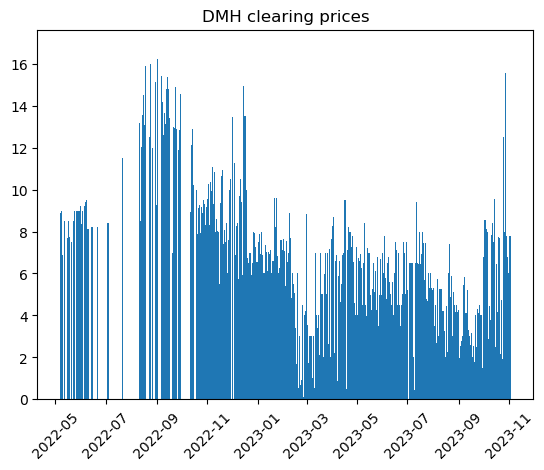

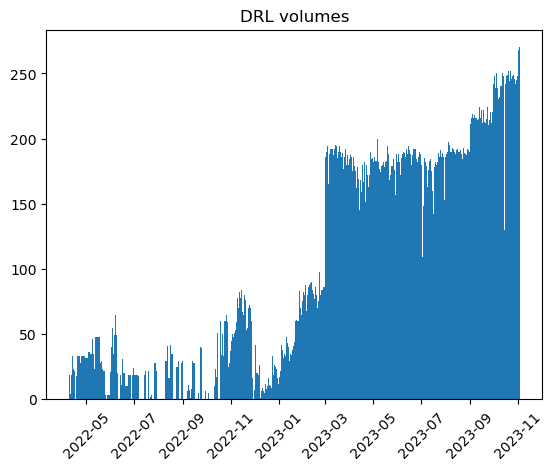

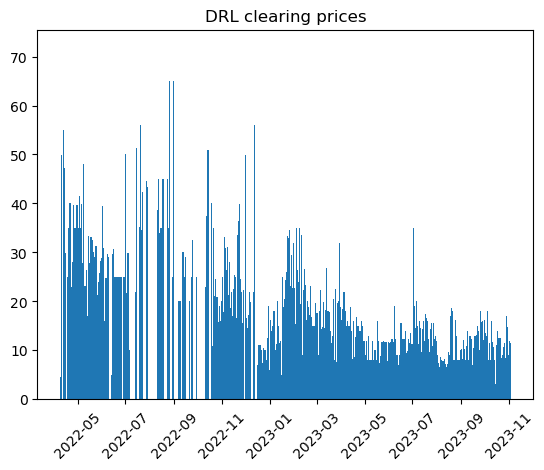

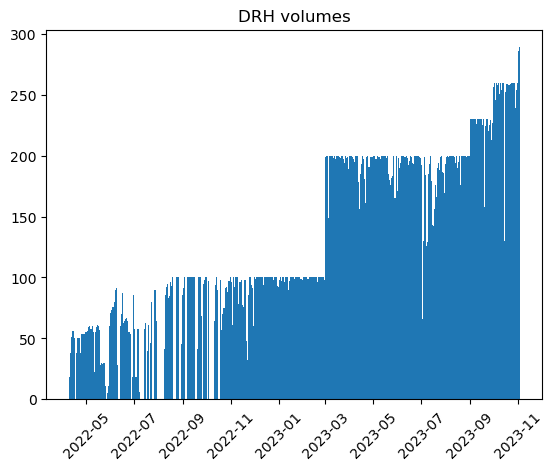

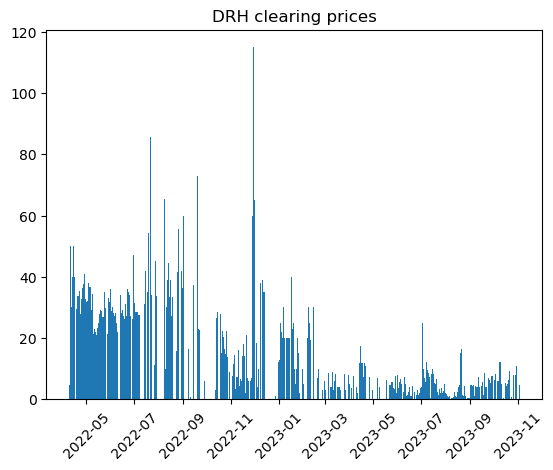

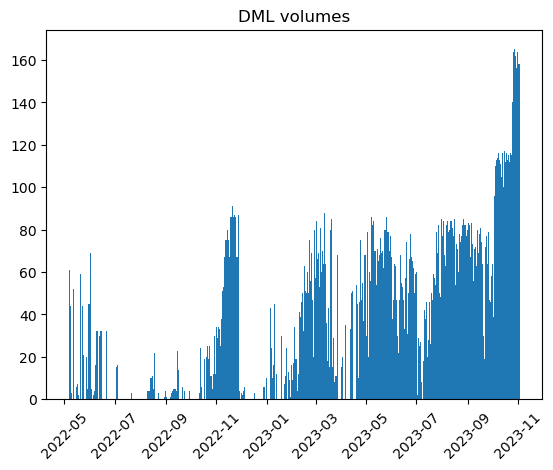

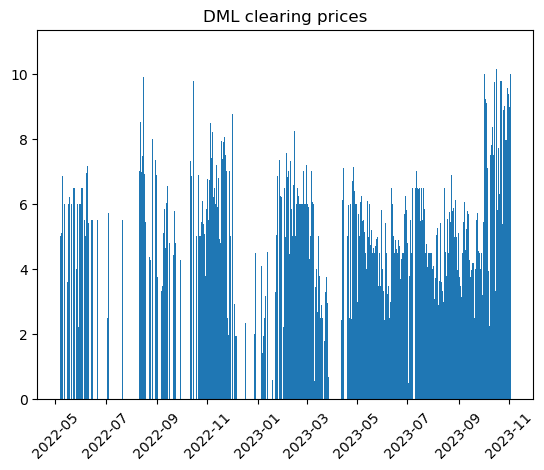

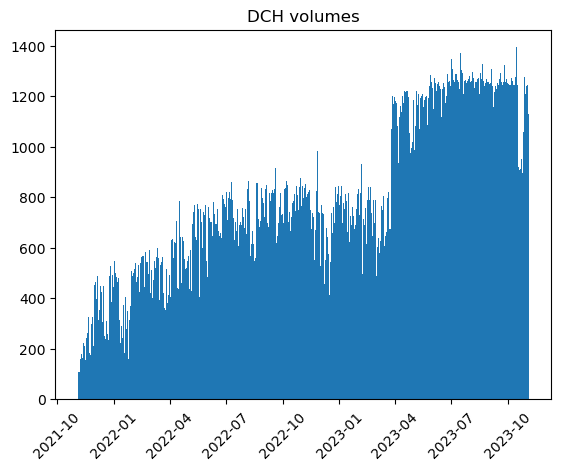

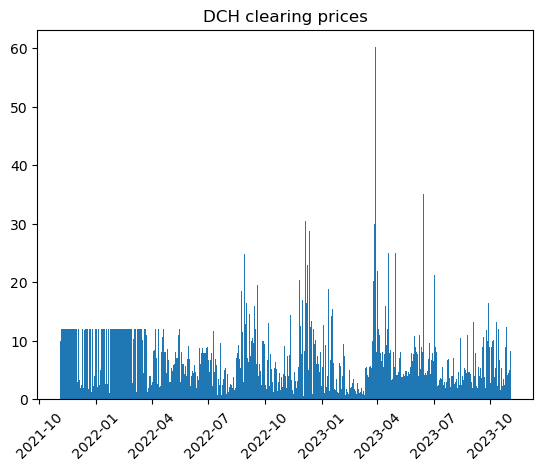

In [50]:


for service in set(pricesNESO['Service']):

    filter_service = pricesNESO[pricesNESO['Service'] == service]
    
    # dates = pd.date_range(filter_service['Delivery Start'].min(), filter_service['Delivery End'].max(),freq='4H')
    # dates = dates[:-1]
    
    y = filter_service['Cleared Volume'].groupby(filter_service['Delivery Start']).sum()
    x = filter_service['Cleared Volume'].groupby(filter_service['Delivery Start']).sum().index

    plt.bar(x, y)
    plt.xticks(rotation=45) 
    plt.title(f'{service} volumes')
    plt.show()
    
    y =  filter_service['Clearing Price'].groupby(filter_service['Delivery Start']).mean()

    plt.bar(x,y)
    plt.title(f'{service} clearing prices')
    plt.xticks(rotation=45) 
    plt.show()


In [51]:
# dates = pd.date_range(pricesNESO['Delivery Start'].min(), pricesNESO['Delivery End'].max(),freq='4H')

# plt.plot(pricesNESO['Cleared Volume'].groupby(pricesNESO['Delivery Start'].dt.date).sum())
# plt.xticks(rotation=45) 
# plt.show()

# plt.plot(pricesNESO['Clearing Price'].groupby(pricesNESO['Delivery Start'].dt.date).mean())
# plt.xticks(rotation=45) 
# plt.show()

In [53]:
pricesNESO1 = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-2023.csv', parse_dates= ['deliveryStart', 'deliveryEnd'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

print(pricesNESO1['deliveryStart'].min(), pricesNESO1['deliveryEnd'].max())
pricesNESO1

2023-11-02 23:00:00 2025-07-23 22:00:00


,auctionID,auctionProduct,serviceType,deliveryStart,deliveryEnd,clearedVolume,clearingPrice,linkedServiceWindowID
0,1,DRH,Response,2023-11-02 23:00:00,2023-11-03 03:00:00,175.0,2.75,NaN
1,1,DRH,Response,2023-11-03 03:00:00,2023-11-03 07:00:00,239.0,4.04,NaN
2,1,DRH,Response,2023-11-03 07:00:00,2023-11-03 11:00:00,290.0,-3.30,NaN
3,1,DRH,Response,2023-11-03 11:00:00,2023-11-03 15:00:00,290.0,-3.53,NaN
4,1,DRH,Response,2023-11-03 15:00:00,2023-11-03 19:00:00,290.0,-5.81,NaN
...,...,...,...,...,...,...,...,...
44907,1448,DMH,Response,2025-07-23 02:00:00,2025-07-23 06:00:00,300.0,1.32,NaN
44908,1448,DMH,Response,2025-07-23 06:00:00,2025-07-23 10:00:00,320.0,-0.21,NaN
44909,1448,DMH,Response,2025-07-23 10:00:00,2025-07-23 14:00:00,300.0,2.70,NaN
44910,1448,DMH,Response,2025-07-23 14:00:00,2025-07-23 18:00:00,300.0,2.05,NaN


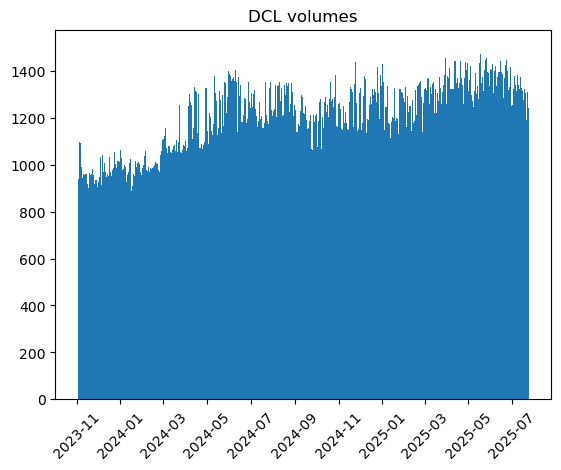

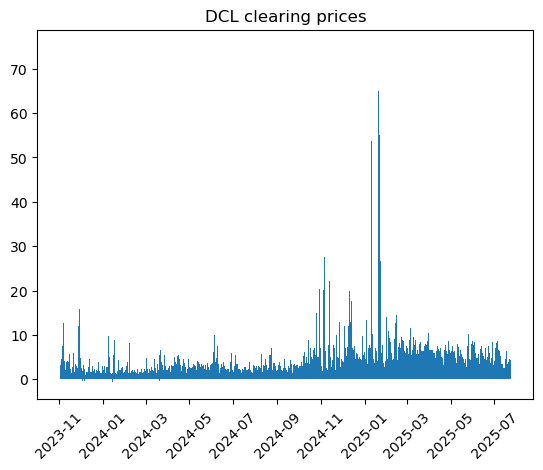

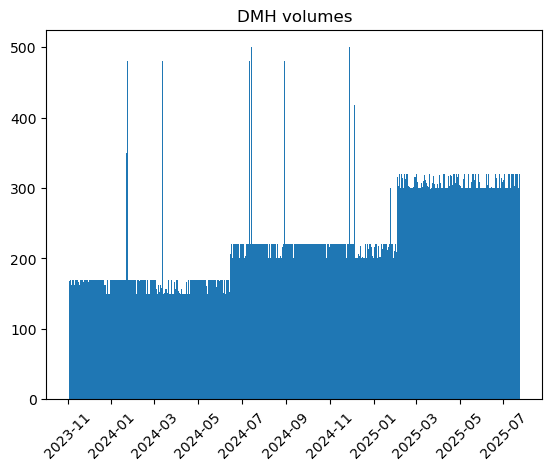

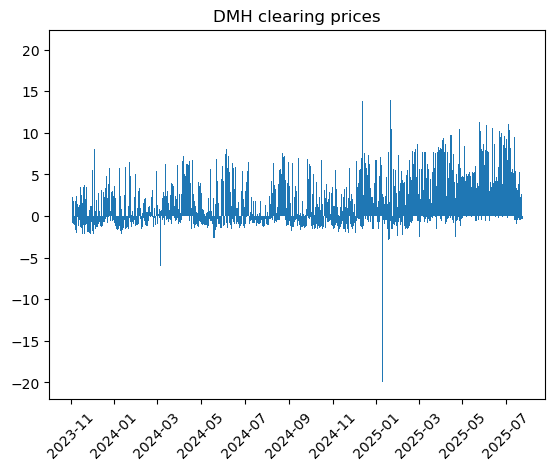

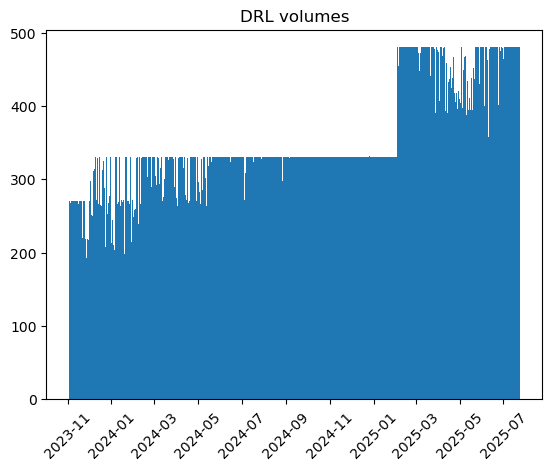

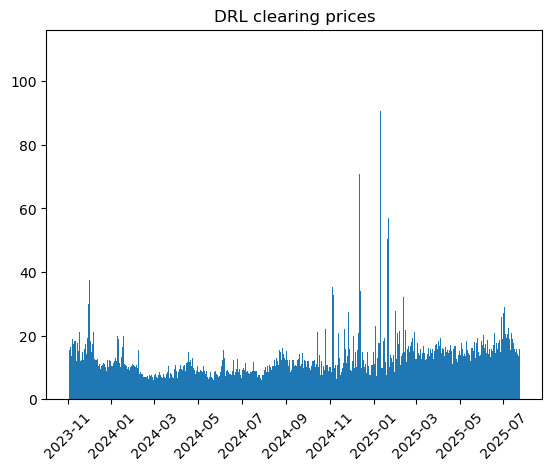

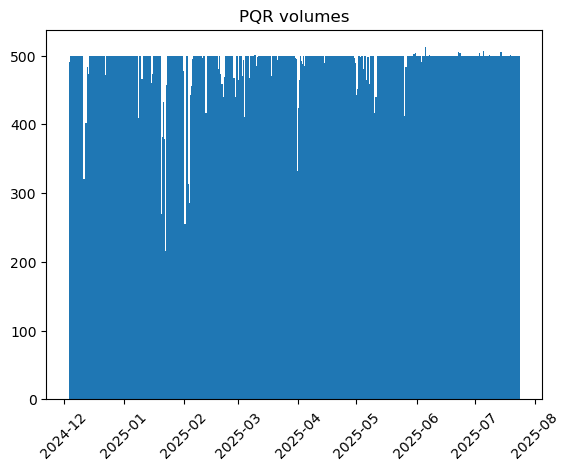

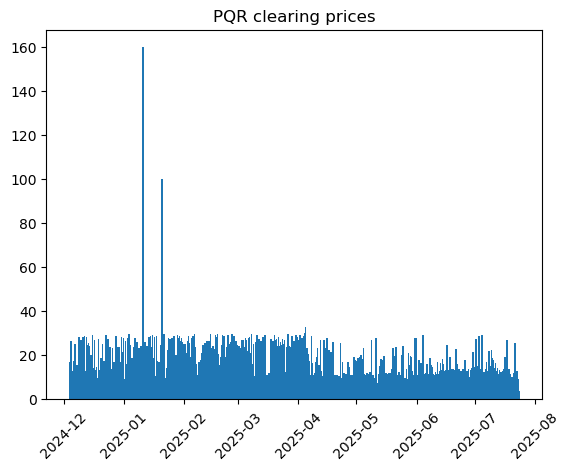

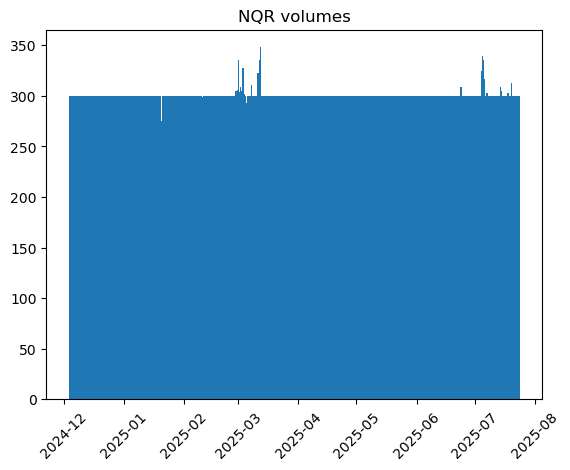

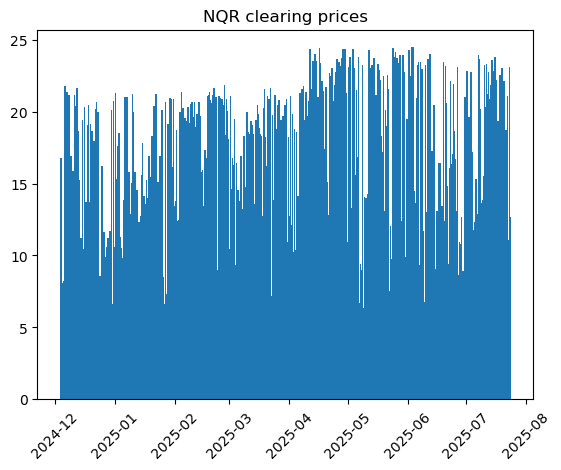

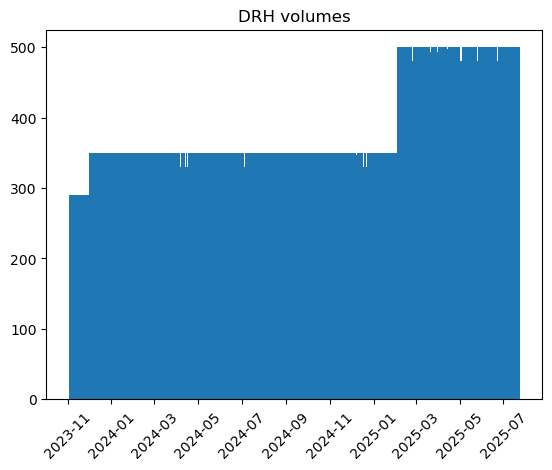

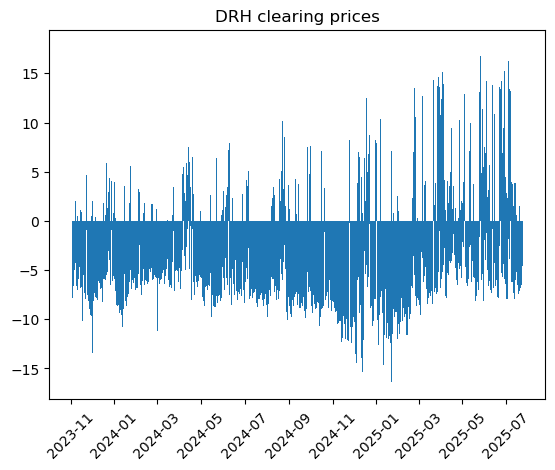

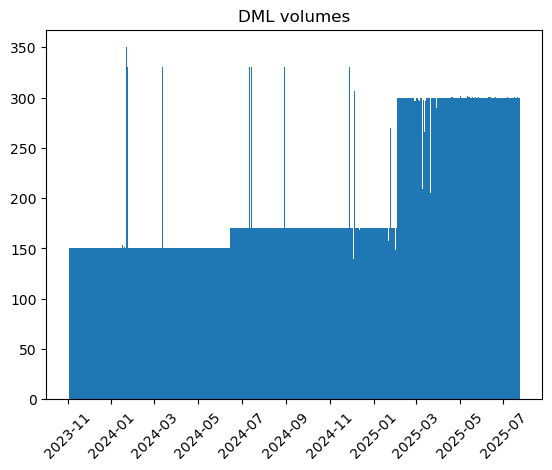

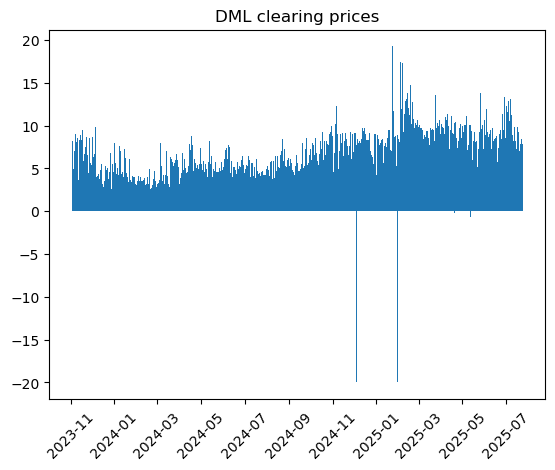

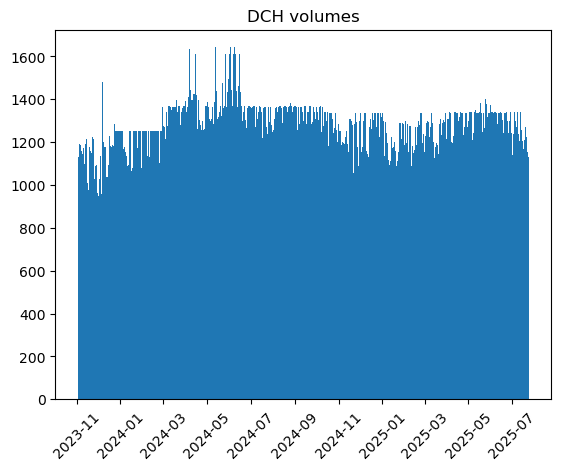

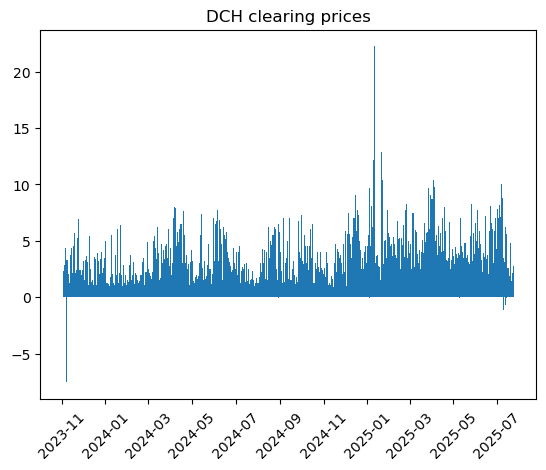

In [57]:

for service in set(pricesNESO1['auctionProduct']):

    filter_service = pricesNESO1[pricesNESO1['auctionProduct'] == service]
    
    # dates = pd.date_range(filter_service['Delivery Start'].min(), filter_service['Delivery End'].max(),freq='4H')
    # dates = dates[:-1]
    
    y = filter_service['clearedVolume'].groupby(filter_service['deliveryStart']).sum()
    x = filter_service['clearedVolume'].groupby(filter_service['deliveryStart']).sum().index

    plt.bar(x, y)
    plt.xticks(rotation=45) 
    plt.title(f'{service} volumes')
    plt.show()
    
    y =  filter_service['clearingPrice'].groupby(filter_service['deliveryStart']).mean()

    plt.bar(x,y)
    plt.title(f'{service} clearing prices')
    plt.xticks(rotation=45) 
    plt.show()


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_18884\2280456238.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


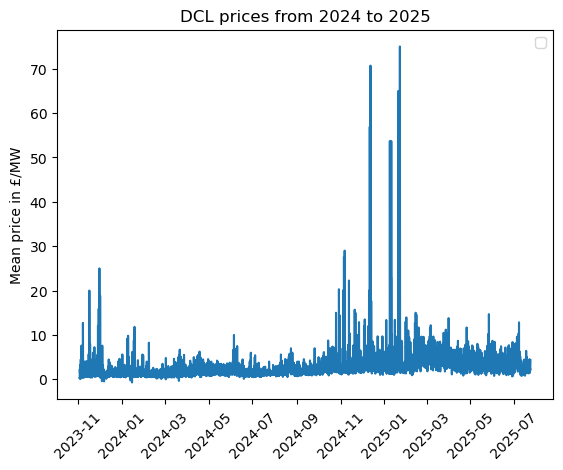

In [21]:
plt.plot(pricesNESO['deliveryStart'], pricesNESO['clearingPrice'])
plt.xticks(rotation=45) 
plt.ylabel('Mean price in £/MW')
plt.title('DCL prices from 2024 to 2025')
plt.legend()
plt.show()

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_18884\2787641816.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


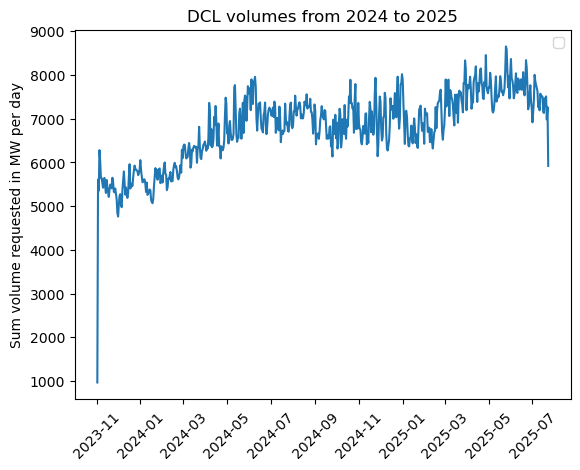

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_18884\2787641816.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


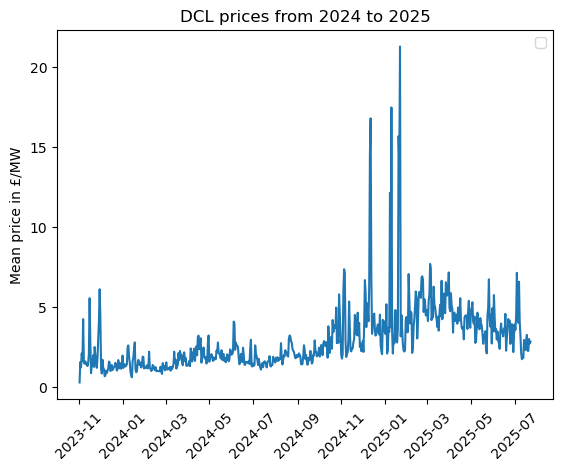

In [ ]:
plt.plot(pricesNESO['clearedVolume'].groupby(pricesNESO['deliveryStart'].dt.date).sum())
plt.xticks(rotation=45) 
plt.ylabel('Sum volume requested in MW per day')
plt.title('DCL volumes from 2024 to 2025')
plt.legend()
plt.show()

plt.plot(pricesNESO['clearingPrice'].groupby(pricesNESO['deliveryStart'].dt.date).mean())
plt.xticks(rotation=45) 
plt.ylabel('Mean price in £/MW')
plt.title('DCL prices from 2024 to 2025')
plt.legend()
plt.show()

In [56]:
pricesNESO = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-past.csv', parse_dates= ['deliveryStart', 'deliveryEnd'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

print(pricesNESO['deliveryStart'].min(), pricesNESO['deliveryEnd'].max())
pricesNESO

2023-11-02 23:00:00 2025-07-23 22:00:00


,registeredAuctionParticipant,auctionUnit,serviceType,auctionProduct,executedQuantity,clearingPrice,deliveryStart,deliveryEnd,technologyType,postCode,unitResultID
0,ARENKO CLEANTECH LIMITED,PNYCB-1,Response,DCH,3.0,5.64,2023-11-03 03:00:00,2023-11-03 07:00:00,NaN,NaN,1#||#137#||#DCH#||#14
1,VEST ENERGY LIMITED,VEST-1,Response,DRL,0.0,12.81,2023-11-03 19:00:00,2023-11-03 23:00:00,NaN,NaN,1#||#23#||#DRL#||#24
2,SMS ENERGY SERVICES LIMITED,BROFB-1,Response,DCH,0.0,1.78,2023-11-03 07:00:00,2023-11-03 11:00:00,NaN,NaN,1#||#112#||#DCH#||#15
3,STATKRAFT MARKETS GMBH,AG-JSTK02,Response,DCH,4.0,3.86,2023-11-02 23:00:00,2023-11-03 03:00:00,NaN,NaN,1#||#16#||#DCH#||#13
4,TESLA MOTORS LIMITED,PILLB-1,Response,DCH,49.0,1.96,2023-11-03 15:00:00,2023-11-03 19:00:00,NaN,NaN,1#||#68#||#DCH#||#17
...,...,...,...,...,...,...,...,...,...,...,...
1036331,LIMEJUMP ENERGY LIMITED,AG-HLIM01,Response,DCH,18.0,0.97,2025-07-22 22:00:00,2025-07-23 02:00:00,Batteries,PO14 2HS,1448#||#8#||#DCH#||#92869
1036332,Arenko Cleantech Limited,CRSSB-1,Response,DCH,7.0,0.94,2025-07-23 06:00:00,2025-07-23 10:00:00,Batteries,L13 7HY,1448#||#1524#||#DCH#||#92871
1036333,GORE STREET ENERGY TRADING LIMITED,GSET-05,Response,DCH,18.0,2.34,2025-07-23 10:00:00,2025-07-23 14:00:00,Batteries,BL9 5BY,1448#||#695#||#DCH#||#92872
1036334,FLEXITRICITY LIMITED,AG-GFLX08,Quick Reserve,PQR,25.0,1.00,2025-07-23 10:00:00,2025-07-23 10:30:00,Batteries,M46 0RY,1448#||#1516#||#PQR#||#92911


In [ ]:
import datetime as dt

(pricesNESO['deliveryStart'].dt.date == pricesNESO['deliveryEnd'].dt.date).sum() ##most bids are for a day's worth of response

911698

In [35]:
pricesNESO['clearingPrice'].groupby(pricesNESO['deliveryStart'].dt.date).sum()

deliveryStart
2023-11-02      946.35
2023-11-03     5972.98
2023-11-04     4679.26
2023-11-05     5168.41
2023-11-06     5048.57
                ...   
2025-07-19    10304.18
2025-07-20    10368.84
2025-07-21    12672.44
2025-07-22    10683.58
2025-07-23     8654.59
Name: clearingPrice, Length: 630, dtype: float64

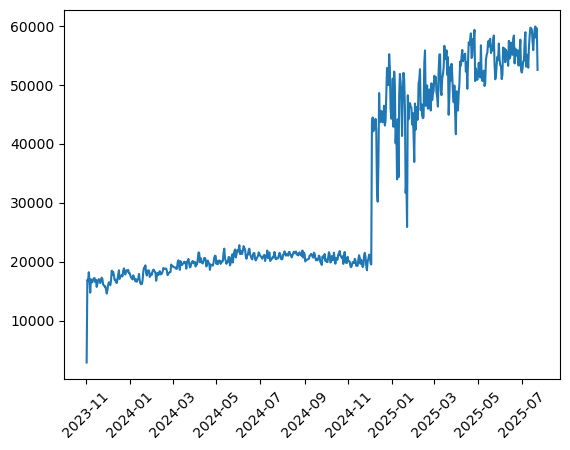

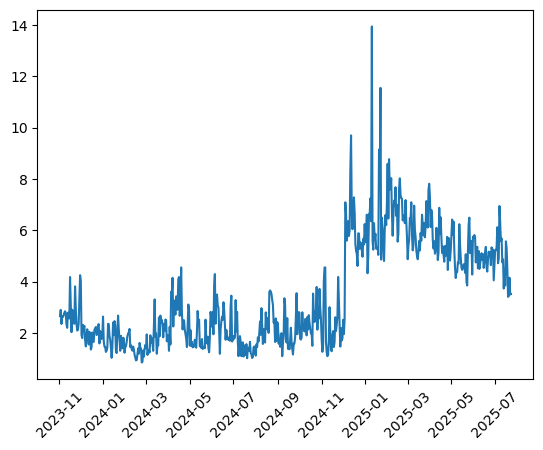

In [58]:
plt.plot(pricesNESO['executedQuantity'].groupby(pricesNESO['deliveryStart'].dt.date).sum())
plt.xticks(rotation=45) 
plt.show()

plt.plot(pricesNESO['clearingPrice'].groupby(pricesNESO['deliveryStart'].dt.date).mean())
plt.xticks(rotation=45) 
plt.show()

### Plotting bonanza



In [ ]:
pricesENAPSYS

NameError: name 'pricesENAPSYS' is not defined

In [ ]:
for col in pricesENAPSYS.columns:
    price_range = pricesENAPSYS[~pricesENAPSYScol].isna()]

    print(col[0])
    print(price_range.index.min().date(), price_range.index.max().date())

PBR
2024-03-12 2025-06-30
NBR
2024-03-12 2025-06-30
DLH
2020-01-01 2021-11-30
Dynamic Containment High
2021-11-03 2025-06-30
Dynamic Containment Low
2020-10-01 2025-06-30
Dynamic FFR
2020-01-01 2023-11-30
Dynamic Moderation High
2022-05-06 2025-06-30
Dynamic Moderation Low
2022-05-06 2025-06-30
Dynamic Regulation High
2022-04-09 2025-06-30
Dynamic Regulation Low
2022-04-09 2025-06-30
EFR
2020-01-01 2022-02-28
Fast Reserve
2020-01-01 2020-03-31
LFS
2020-01-01 2021-11-30
PQR
2024-12-03 2025-06-30
NQR
2024-12-03 2025-06-30
Static FFR
2020-01-01 2025-06-30
STOR (DAY AHEAD)
2021-04-01 2025-06-30
STOR (HISTORIC)
NaT NaT
NIV CHASING 1HR PER DAY EQUIV
2020-01-01 2025-04-20
MIDP 1HR PER DAY EQUIV
2020-01-01 2025-04-20
DAY-AHEAD 1HR PER DAY EQUIV
2020-01-01 2025-04-20
HHRPD 1HR PER DAY EQUIV
2020-01-01 2025-04-20


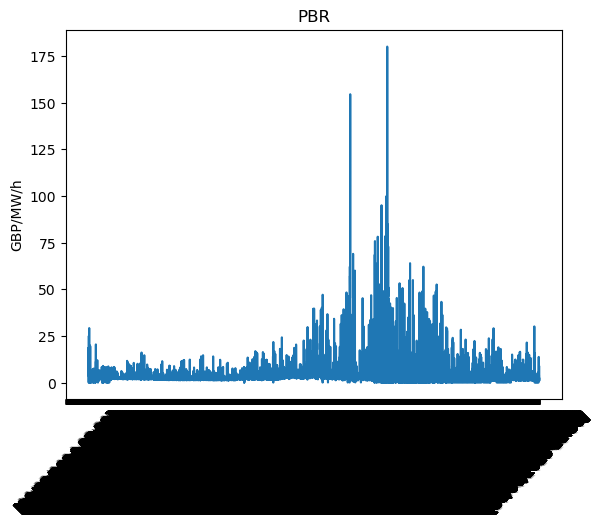

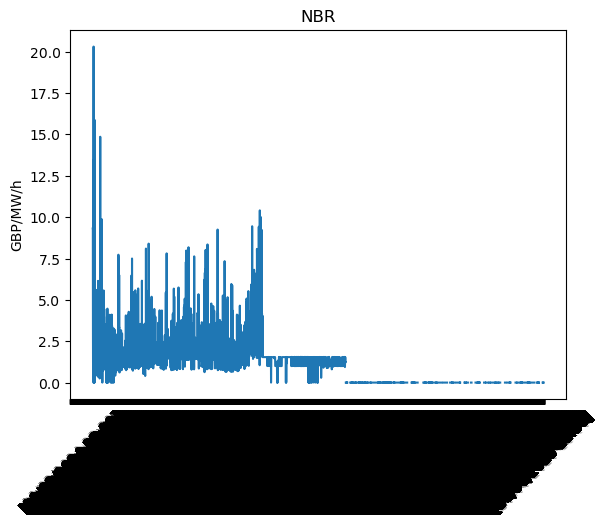

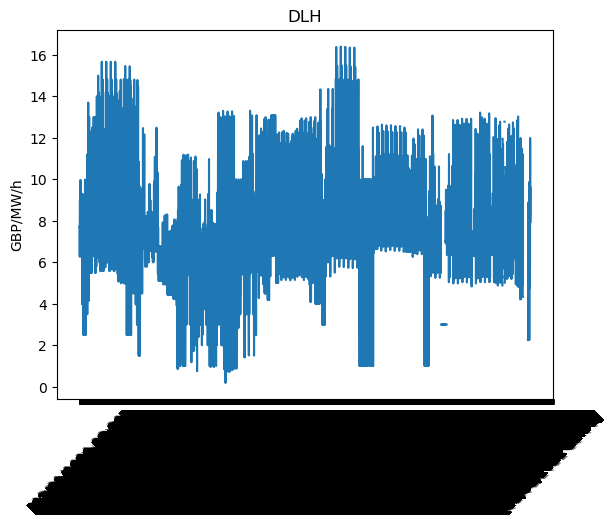

KeyboardInterrupt: 

: 

In [ ]:
for col in prices.columns:
    plt.plot(prices[col])
    plt.title(col[0])
    plt.ylabel(col[1])
    plt.xticks(rotation=45)
    plt.show()

In [25]:
volumes = pd.read_csv(path_dir / 'data/volumes-ancillary-elec_ENAPSYS.csv', index_col=0, header=[0, 1])
volumes.index = pd.to_datetime(volumes.index.str.replace(r'[\[\]\(\)\{\}]', '', regex=True),
                              dayfirst = True)
volumes

Date (WET),PBR,NBR,DLH,Dynamic Containment High,Dynamic Containment Low,Dynamic FFR,Dynamic Moderation High,Dynamic Moderation Low,Dynamic Regulation High,Dynamic Regulation Low,...,Fast Reserve,LFS,MFR High,MFR Primary,MFR Secondary,PQR,NQR,Static FFR,STOR (DAY AHEAD),STOR (HISTORIC)
,MW,MW,MW,MW,MW,MW,MW,MW,MW,MW,...,MW,MW,MW,MW,MW,MW,MW,MW,MW,MW
2020-01-01 00:00:00,NaN,NaN,80.0,NaN,NaN,406.0,NaN,NaN,NaN,NaN,...,94.0,31.0,405.6,340.9,223.9,NaN,NaN,0.0,NaN,NaN
2020-01-01 00:30:00,NaN,NaN,80.0,NaN,NaN,406.0,NaN,NaN,NaN,NaN,...,94.0,31.0,405.6,340.9,223.9,NaN,NaN,0.0,NaN,NaN
2020-01-01 01:00:00,NaN,NaN,80.0,NaN,NaN,406.0,NaN,NaN,NaN,NaN,...,94.0,31.0,405.6,340.9,223.9,NaN,NaN,0.0,NaN,NaN
2020-01-01 01:30:00,NaN,NaN,80.0,NaN,NaN,406.0,NaN,NaN,NaN,NaN,...,94.0,31.0,405.6,340.9,223.9,NaN,NaN,0.0,NaN,NaN
2020-01-01 02:00:00,NaN,NaN,80.0,NaN,NaN,406.0,NaN,NaN,NaN,NaN,...,94.0,31.0,405.6,340.9,223.9,NaN,NaN,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-30 21:30:00,560.0,NaN,NaN,848.0,2235.0,NaN,-617.0,586.0,-916.0,800.0,...,NaN,NaN,392.3,290.7,177.8,38.0,-96.0,250.0,1584.0,NaN
2025-06-30 22:00:00,227.0,NaN,NaN,839.0,2219.0,NaN,-570.0,599.0,-904.0,774.0,...,NaN,NaN,392.3,290.7,177.8,69.0,-141.0,250.0,0.0,NaN
2025-06-30 22:30:00,227.0,NaN,NaN,839.0,2219.0,NaN,-570.0,599.0,-904.0,774.0,...,NaN,NaN,392.3,290.7,177.8,20.0,-112.0,250.0,0.0,NaN


In [26]:
prices = pd.read_csv(path_dir / 'data/prices-ancillary-elec_ENAPSYS.csv', index_col=0, header=[0, 1])
prices.index = pd.to_datetime(prices.index.str.replace(r'[\[\]\(\)\{\}]', '', regex=True),
                              dayfirst = True)
prices

Date (WET),PBR,NBR,DLH,Dynamic Containment High,Dynamic Containment Low,Dynamic FFR,Dynamic Moderation High,Dynamic Moderation Low,Dynamic Regulation High,Dynamic Regulation Low,...,LFS,PQR,NQR,Static FFR,STOR (DAY AHEAD),STOR (HISTORIC),NIV CHASING 1HR PER DAY EQUIV,MIDP 1HR PER DAY EQUIV,DAY-AHEAD 1HR PER DAY EQUIV,HHRPD 1HR PER DAY EQUIV
,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,...,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/h,GBP/MW/d,GBP/MW/d,GBP/MW/d,GBP/MW/d
2020-01-01 00:00:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.22,0.0,0.0,0.0
2020-01-01 00:30:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.23,0.0,0.0,0.0
2020-01-01 01:00:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.00,0.0,0.0,0.0
2020-01-01 01:30:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.00,0.0,0.0,0.0
2020-01-01 02:00:00,NaN,NaN,7.73,NaN,NaN,9.62,NaN,NaN,NaN,NaN,...,5.04,NaN,NaN,2.50,NaN,NaN,0.00,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-30 21:30:00,3.37,NaN,NaN,0.79,6.70,NaN,-0.32,11.54,-10.45,27.47,...,NaN,13.88,1.0,7.00,1.49,NaN,NaN,NaN,NaN,NaN
2025-06-30 22:00:00,1.00,NaN,NaN,1.60,2.12,NaN,0.43,6.17,-8.22,17.89,...,NaN,6.74,1.0,7.00,NaN,NaN,NaN,NaN,NaN,NaN
2025-06-30 22:30:00,1.00,NaN,NaN,1.60,2.12,NaN,0.43,6.17,-8.22,17.89,...,NaN,6.60,1.0,7.00,NaN,NaN,NaN,NaN,NaN,NaN


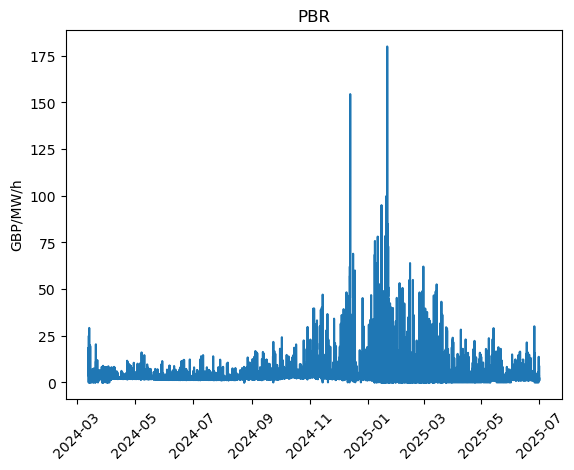

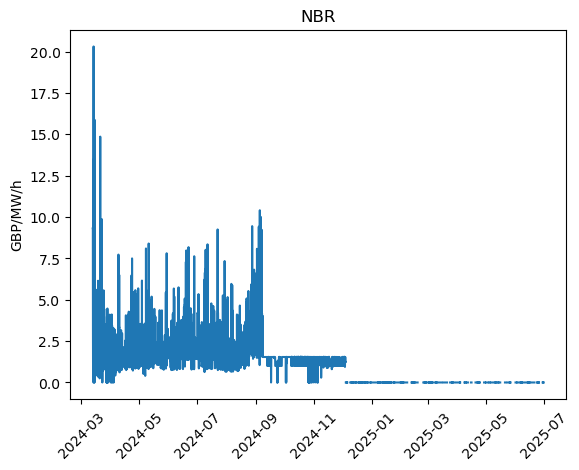

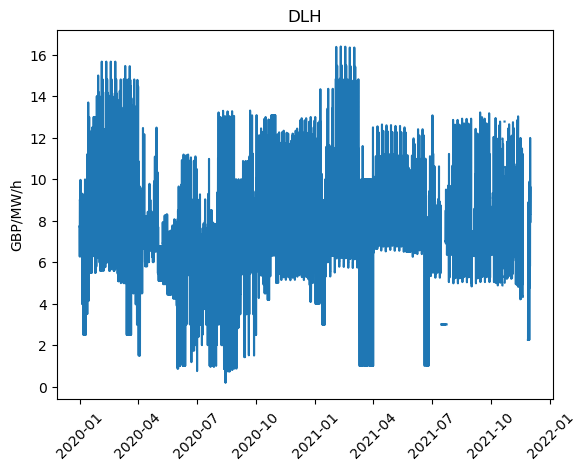

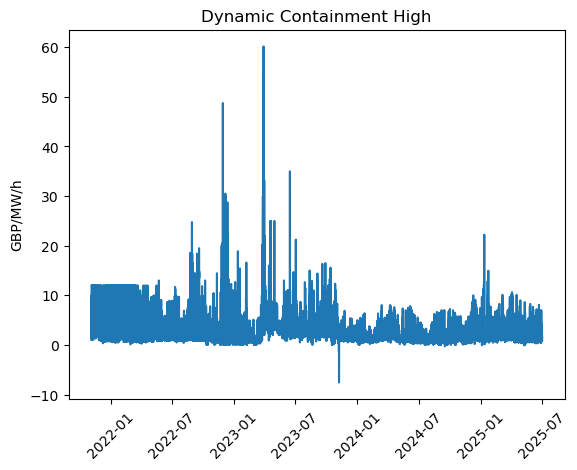

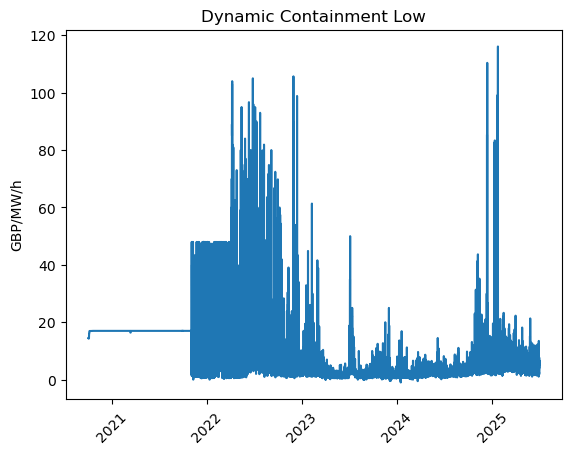

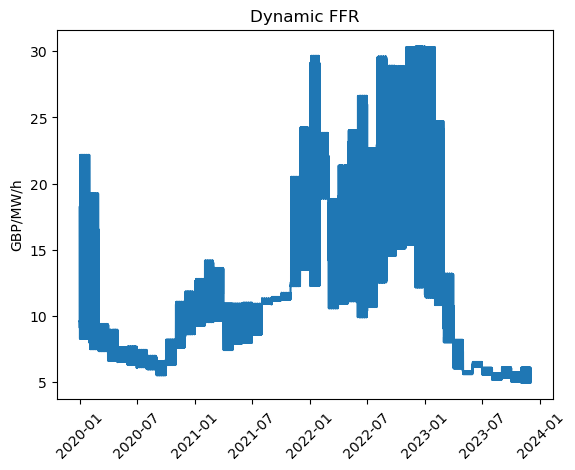

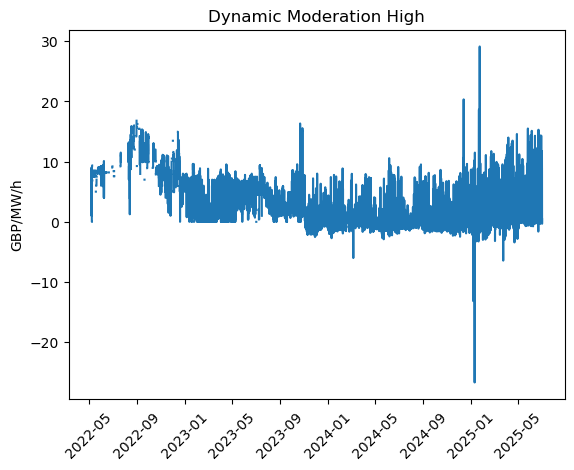

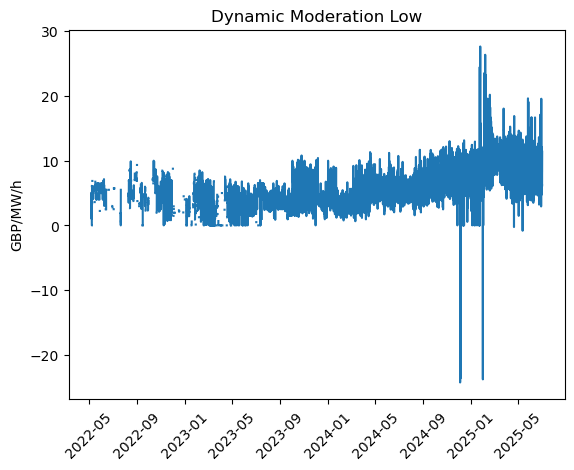

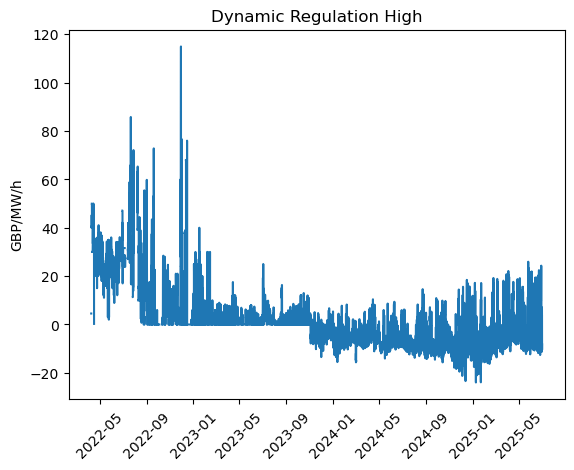

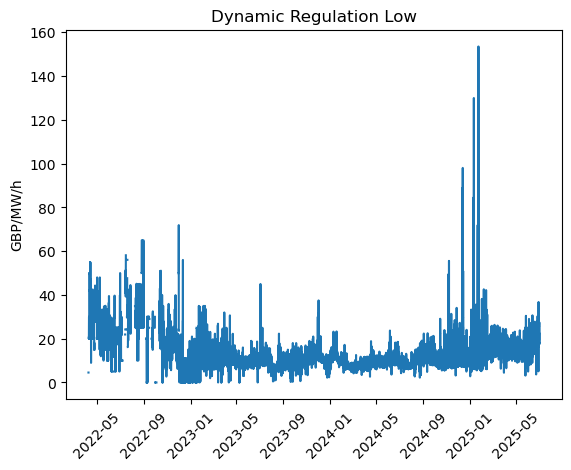

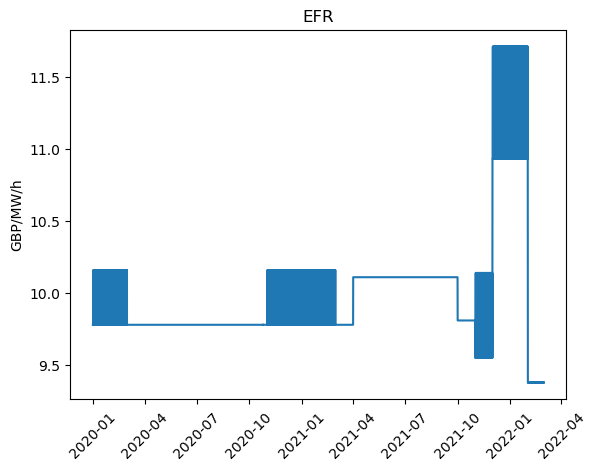

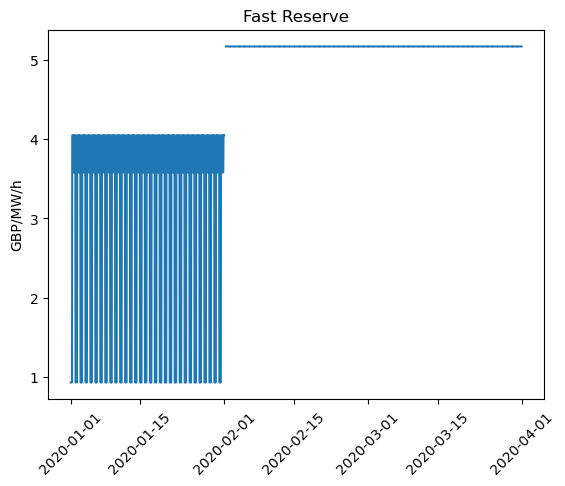

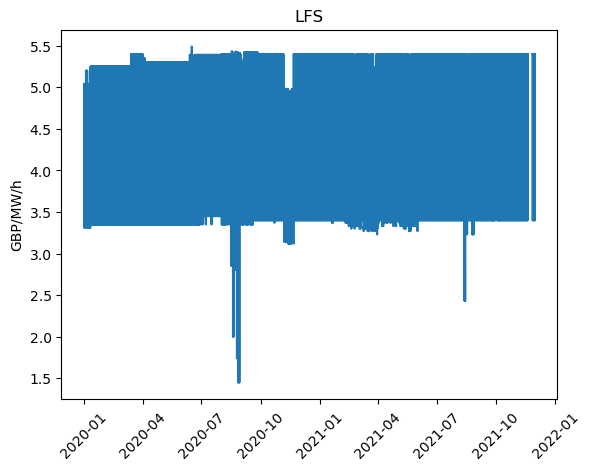

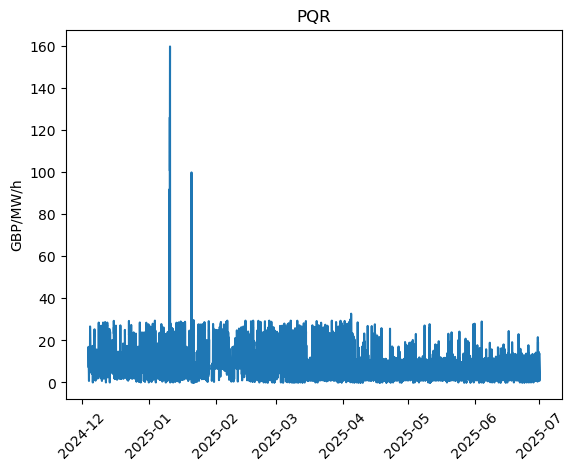

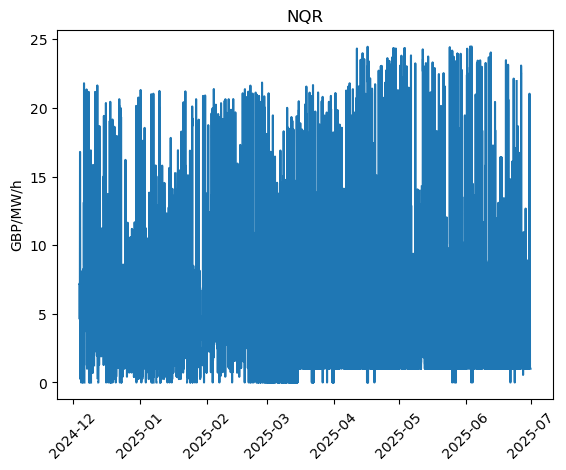

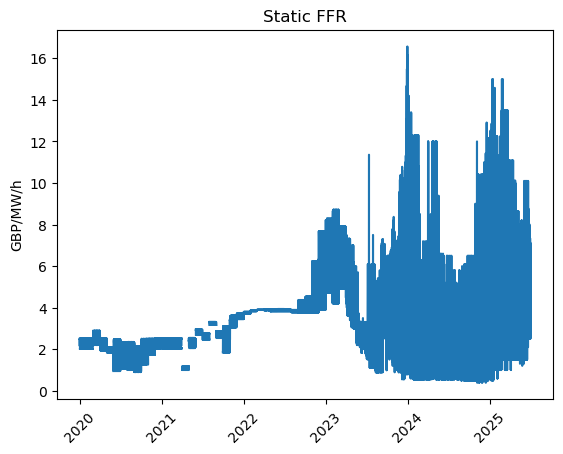

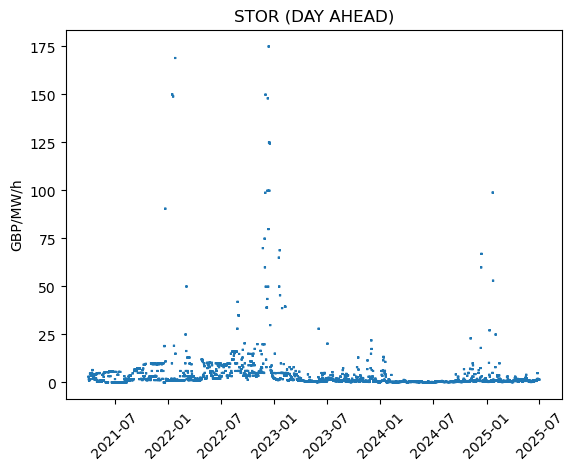

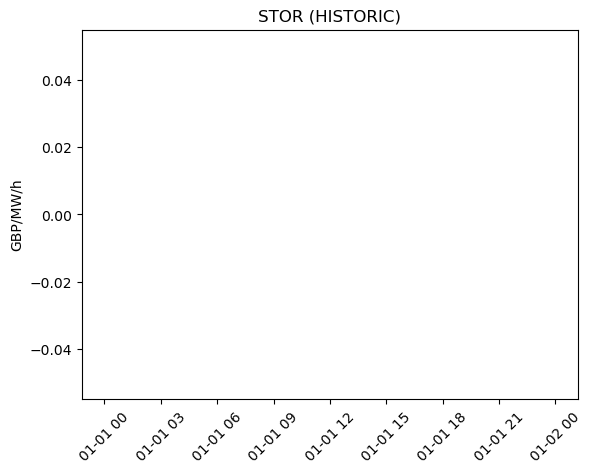

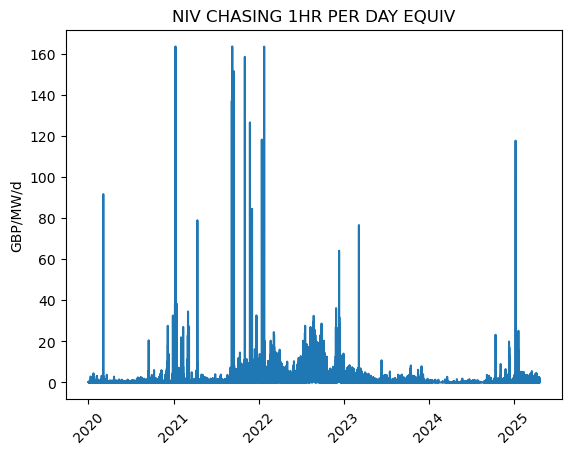

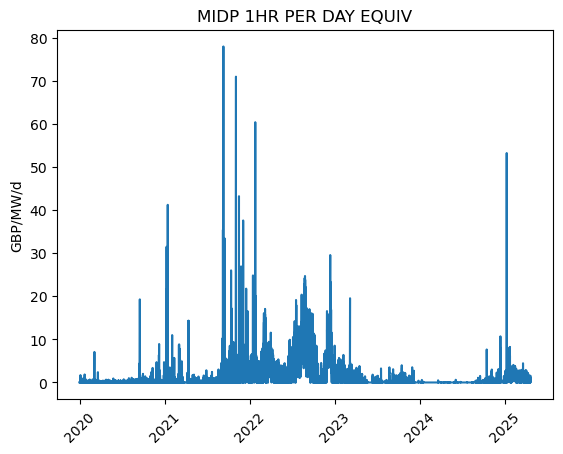

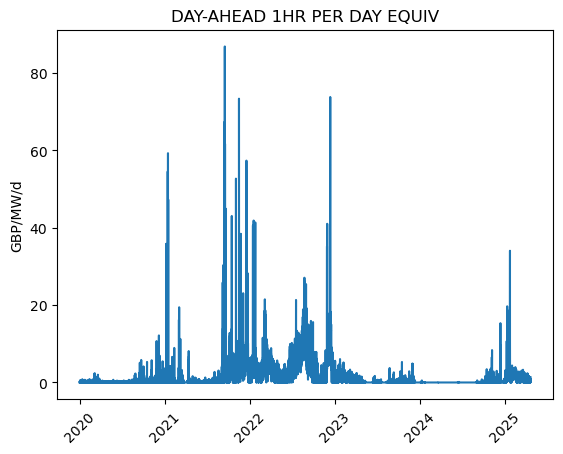

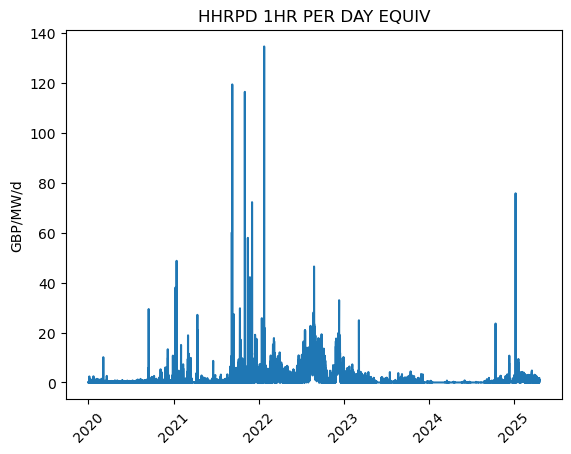

In [27]:
for col in prices.columns:
    plt.plot(prices[col])
    plt.title(col[0])
    plt.ylabel(col[1])
    plt.xticks(rotation=45)
    plt.show()

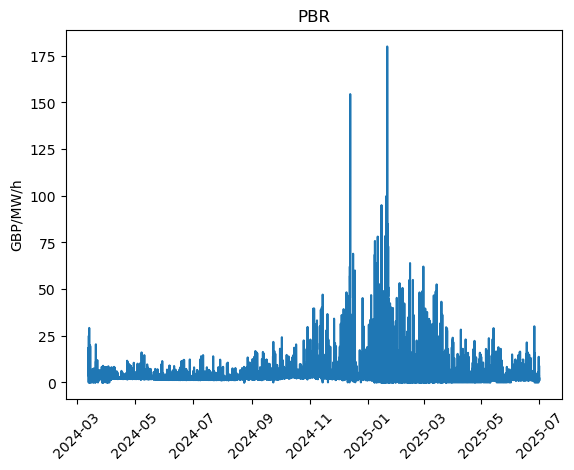

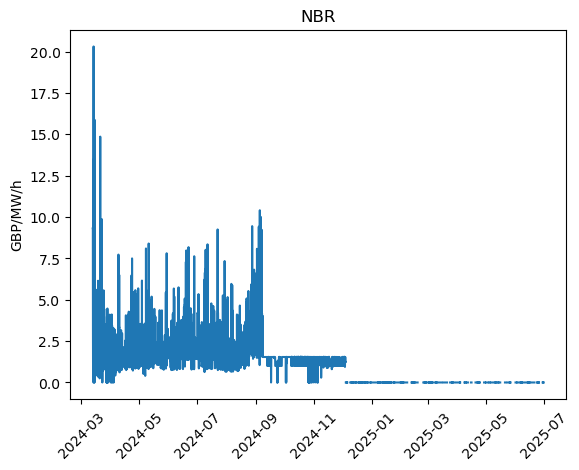

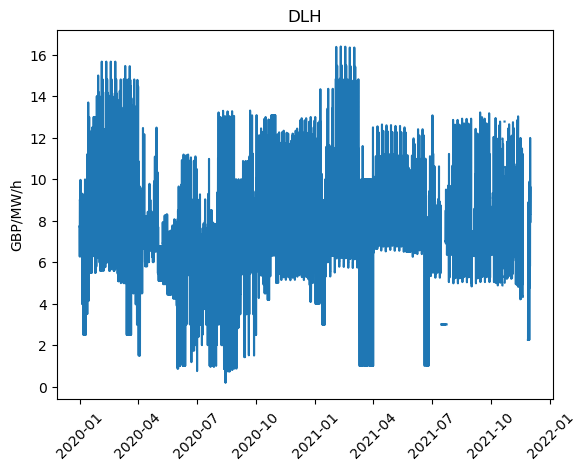

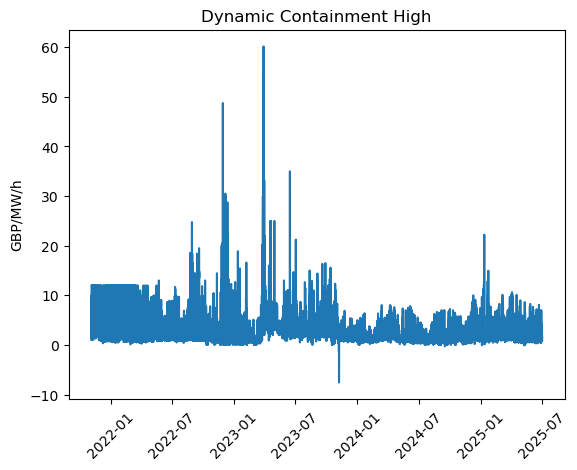

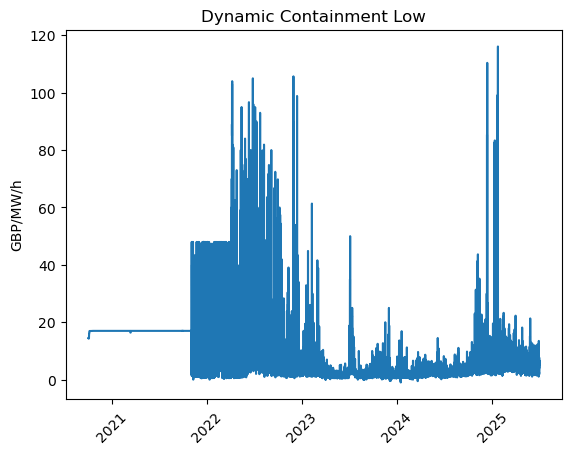

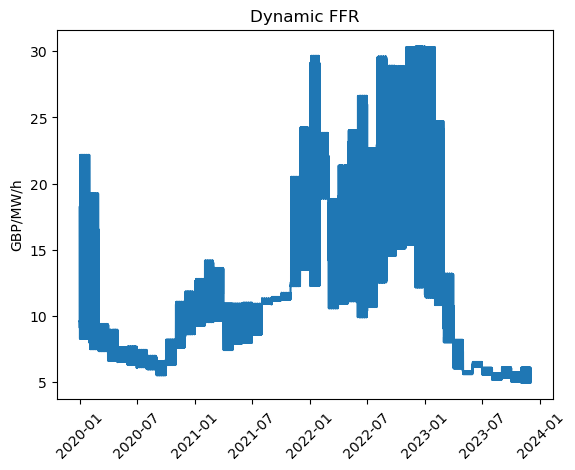

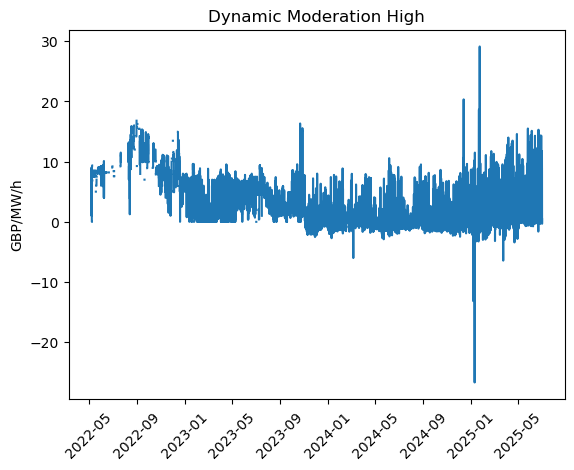

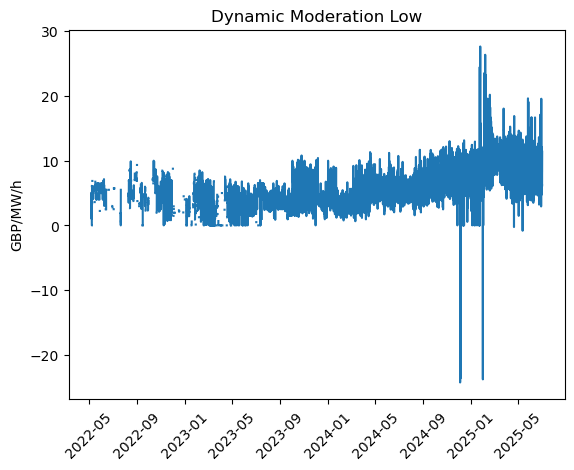

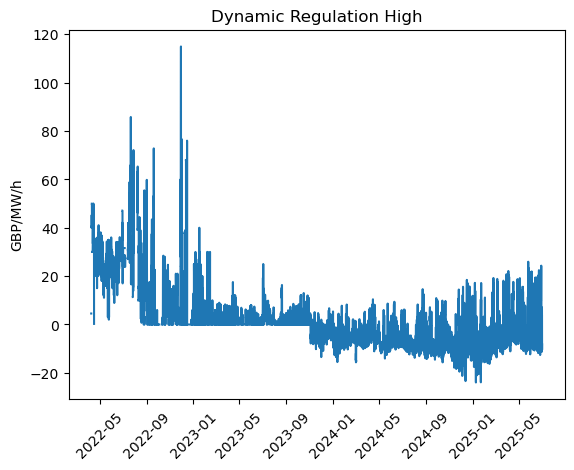

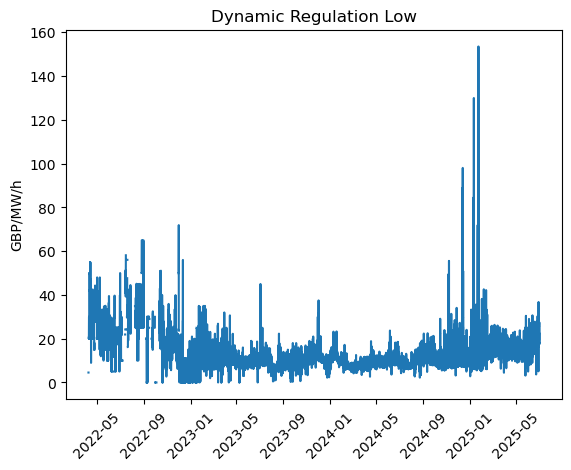

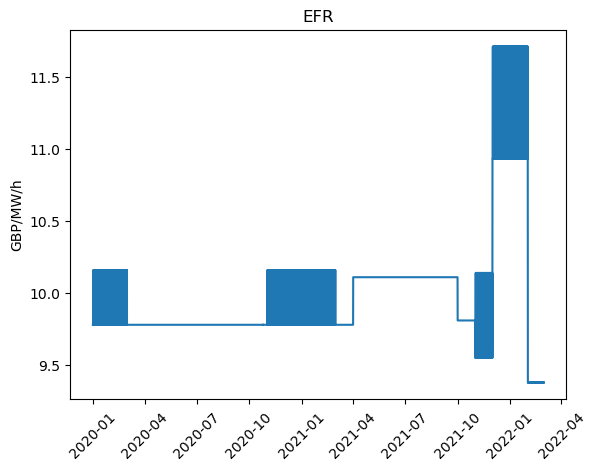

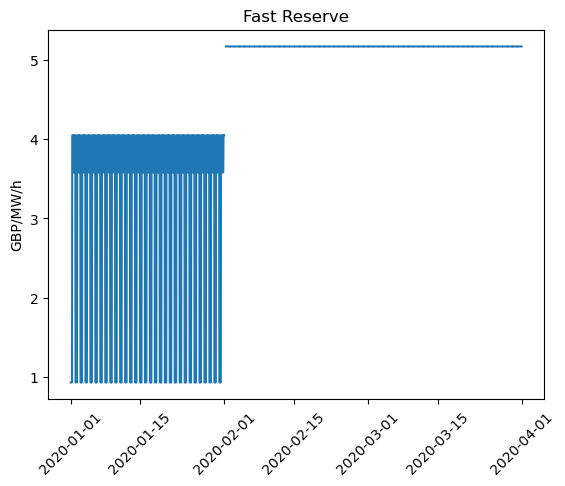

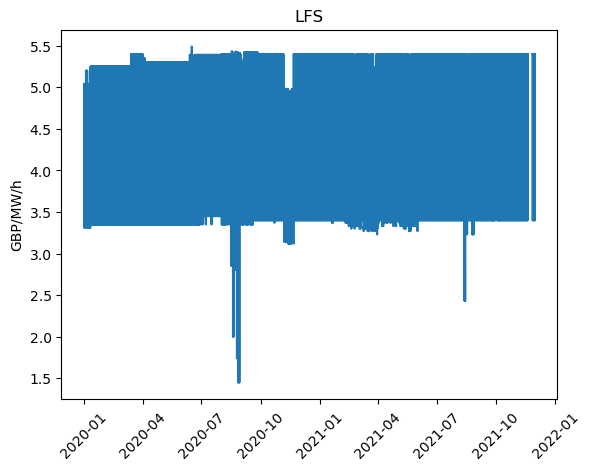

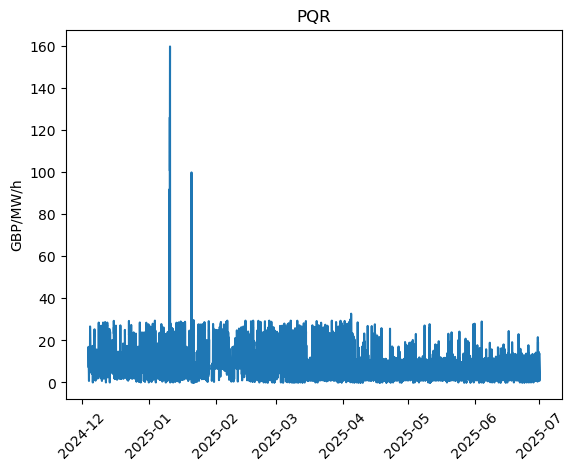

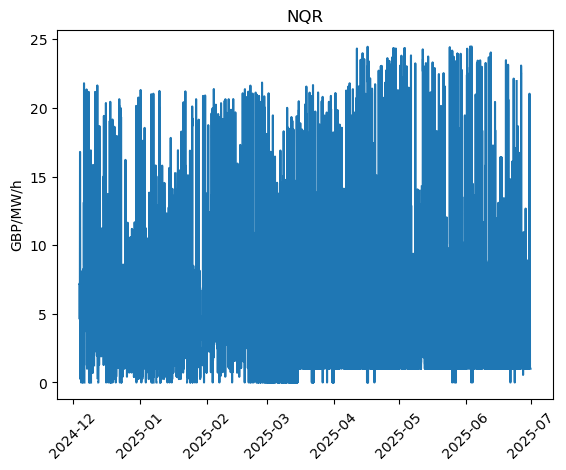

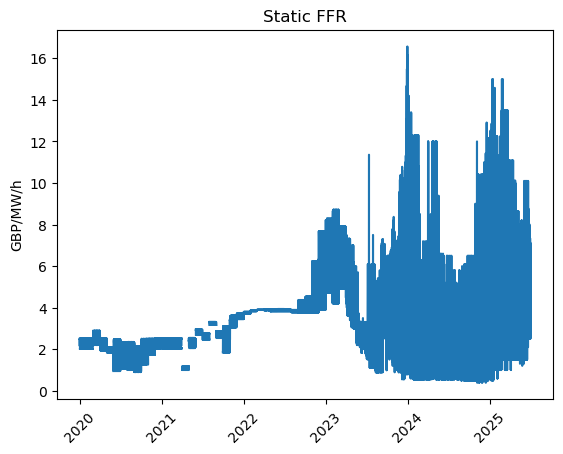

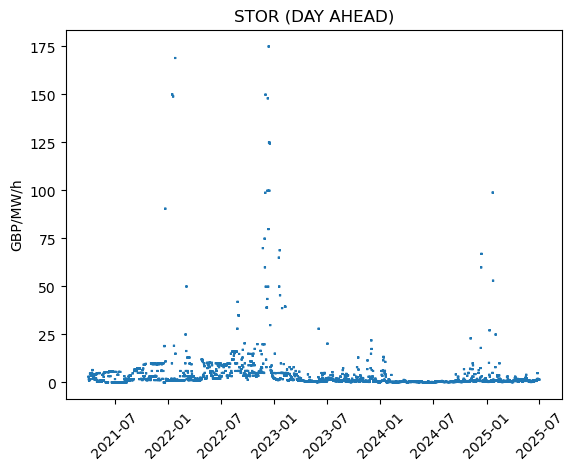

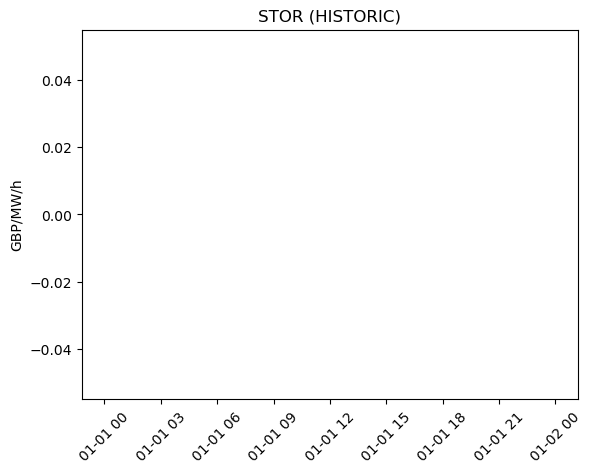

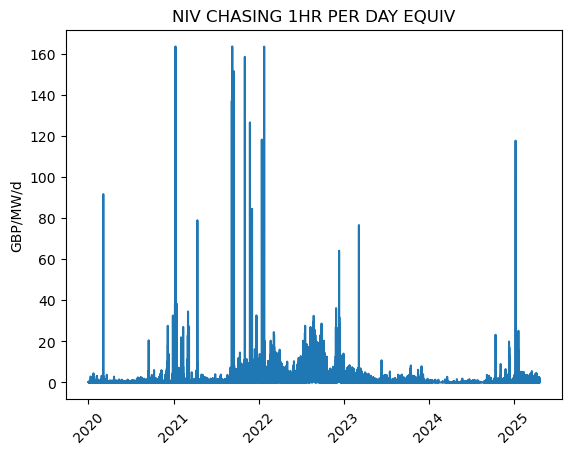

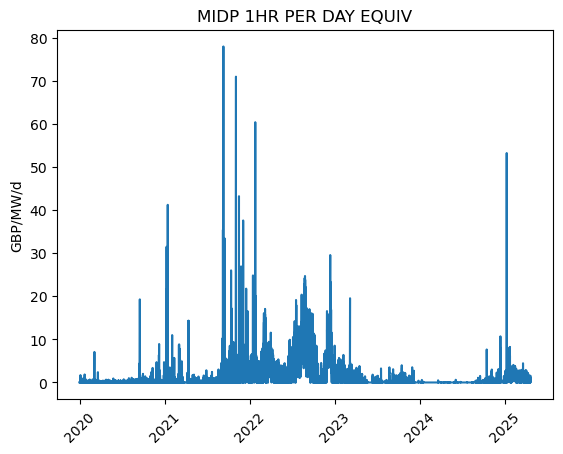

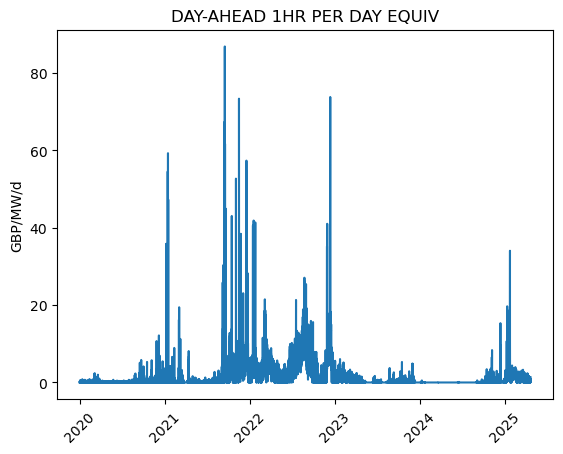

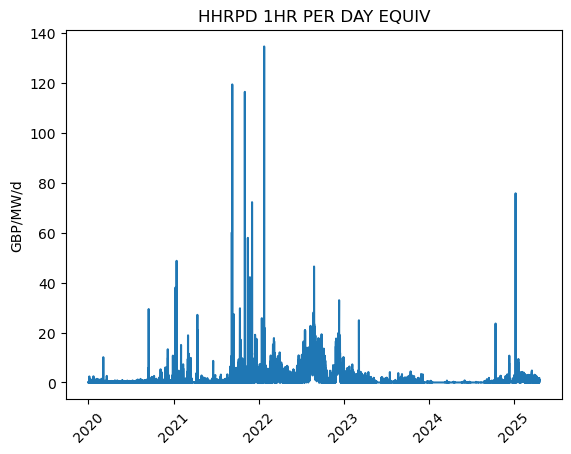

In [33]:
for col in volumes.columns:
    plt.plot(volumes[col])
    plt.title(col[0])
    plt.ylabel(col[1])
    plt.xticks(rotation=45)
    plt.show()

In [15]:
assert((prices.columns == volumes.columns).all())
prices.columns

MultiIndex([(                          'PBR', 'GBP/MW/h'),
            (                          'NBR', 'GBP/MW/h'),
            (                          'DLH', 'GBP/MW/h'),
            (     'Dynamic Containment High', 'GBP/MW/h'),
            (      'Dynamic Containment Low', 'GBP/MW/h'),
            (                  'Dynamic FFR', 'GBP/MW/h'),
            (      'Dynamic Moderation High', 'GBP/MW/h'),
            (       'Dynamic Moderation Low', 'GBP/MW/h'),
            (      'Dynamic Regulation High', 'GBP/MW/h'),
            (       'Dynamic Regulation Low', 'GBP/MW/h'),
            (                          'EFR', 'GBP/MW/h'),
            (                 'Fast Reserve', 'GBP/MW/h'),
            (                          'LFS', 'GBP/MW/h'),
            (                          'PQR', 'GBP/MW/h'),
            (                          'NQR', 'GBP/MW/h'),
            (                   'Static FFR', 'GBP/MW/h'),
            (             'STOR (DAY AHEAD)', 'GBP/MW/h'

In [ ]:
# PBR : Primary Balancing Responsible;  The Balancing Responsible Party who financially responsible for balancing a specific supply/demand position
# NBR : Named Balancing Responsible;  The Balancing Responsible Party assigned for a particular meter or connection point
# DLH :  Distribution License Holder; DNO
# LFS : Local flex service; DSO
# PQR – Pre-Qualification Report ????
# NQR – Notification of Qualification Result : outcome of the DSO’s evaluation of the PQR lke are they qualified to offer service

#STOR (Day Ahead) tells you how much reserve is planned and available.
#STOR (Historic) shows what was actually used — useful for tracking system stress events, aggregator performance, and market efficiency.
